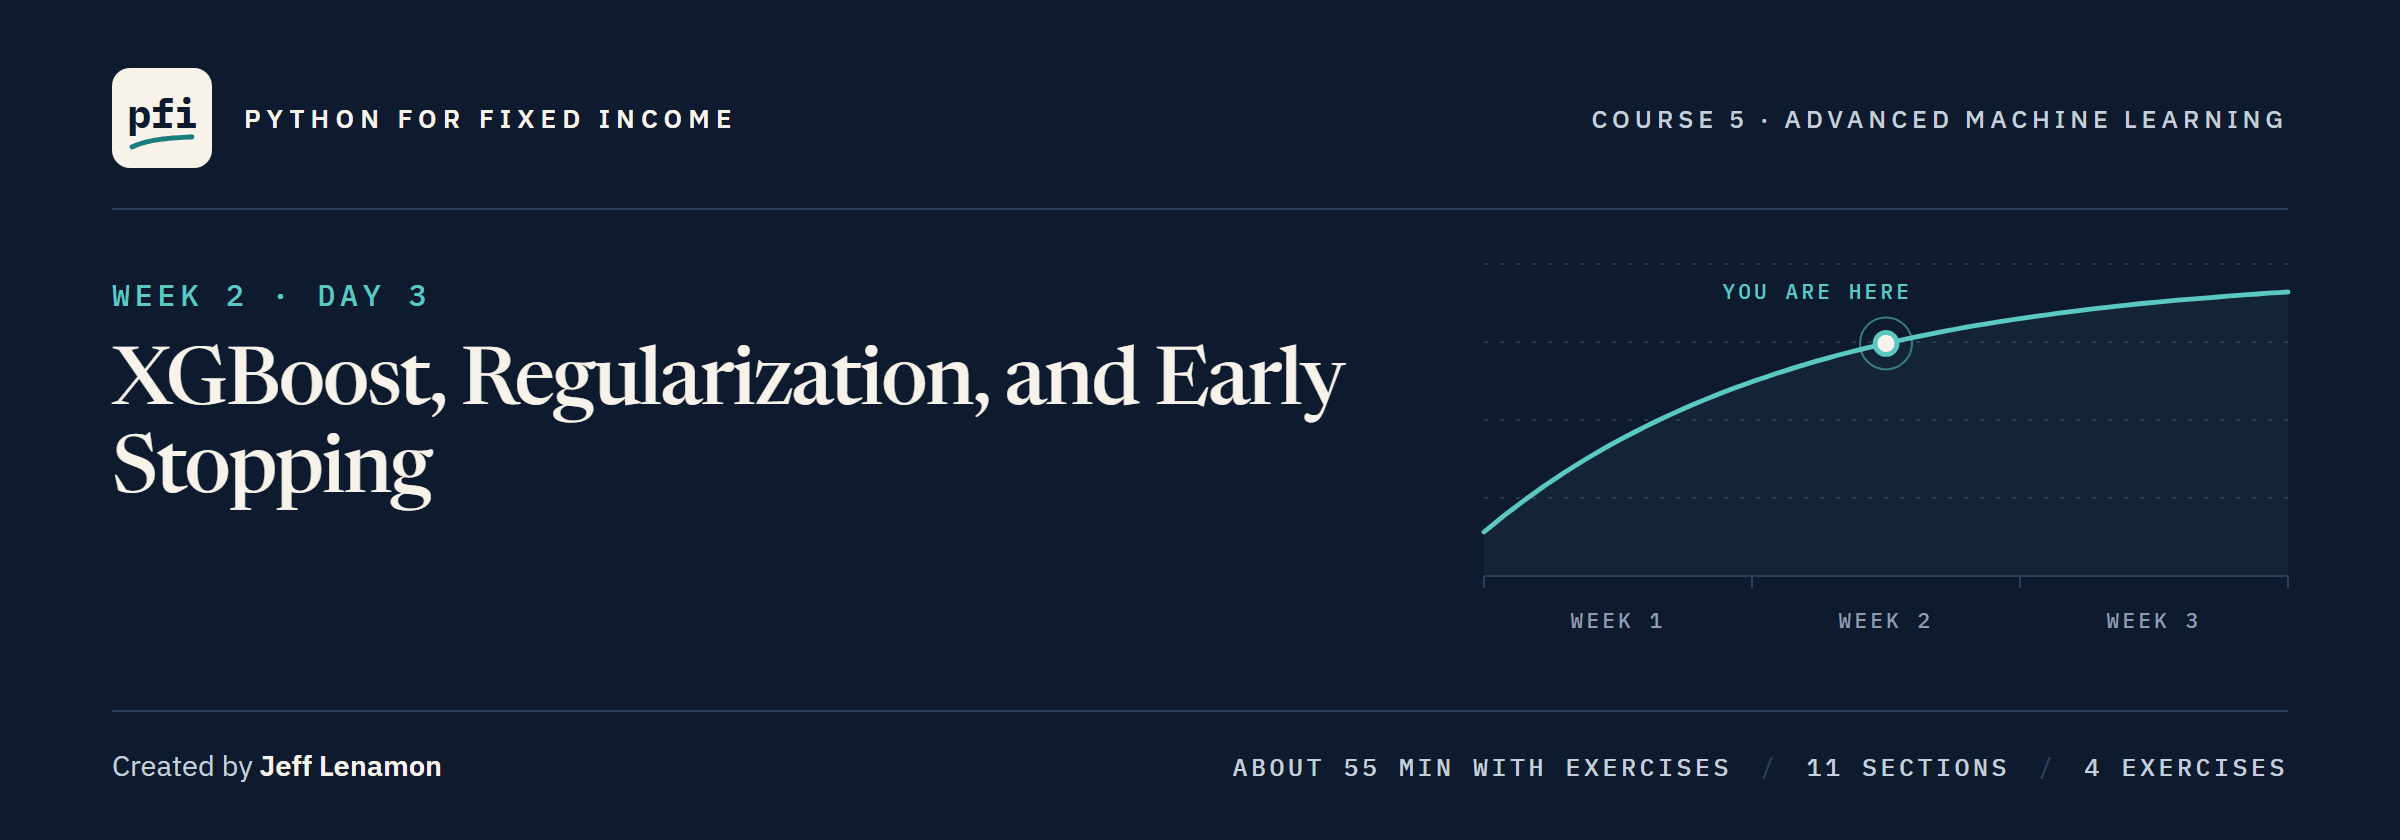

# XGBoost, Regularization, and Early Stopping

Week 2, Day 3. Fit XGBoost on the card accounts, watch its defaults memorise them tree by tree, stop the trees on rows carved from the training rows, and open one tree to see the brakes at work.

**Data:** `credit_card_default.csv`, 30,000 card accounts in Taiwan in 2005: **real**, UCI Machine Learning Repository dataset 350, CC BY 4.0. Citation: Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week2/day3/08_xgboost_regularization_and_early_stopping.ipynb)

# Problem Statement

## Business Context

Day 7 built gradient boosting from residuals on bonds and named scikit-learn's version for a yes-or-no target.
The desk now runs XGBoost, the boosting library many teams reach for first, on Course 4's card accounts.
It needs two answers: how many trees to keep, and how to stop trees six questions deep from memorising 18,000 accounts.
The accounts are real, from Taiwan in 2005, so they describe consumer credit there and then, not US credit today.
The four person columns are never features, because a model that used them would sort people by them.

## Objectives

Fit XGBoost and score it on training and validation rows, follow its scores tree by tree, and stop the trees on rows carved from the training rows.
Rebuild a leaf's value and a split's gain by hand, measure each brake on five folds inside the training rows, weight the rare class, and compare XGBoost with the course's earlier models.

## Data Dictionary

`credit_card_default.csv`, one row per account:

1. `LIMIT_BAL`: credit limit, NT dollars
2. `PAY_0`, `PAY_2` to `PAY_6`: repayment status, September back to April 2005, where -1 is paid on time, 1 to 9 is months late, and -2 and 0 are undocumented (used as numbers, a modelling choice, as in Course 4)
3. `BILL_AMT1` to `BILL_AMT6`: the bill, NT dollars, September back to April
4. `PAY_AMT1` to `PAY_AMT6`: the amount paid, NT dollars, September back to April
5. `default payment next month`: 1 if the account defaulted the following month, **the target**
6. `ID`, `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`: never used

## Your Route Through Day 3

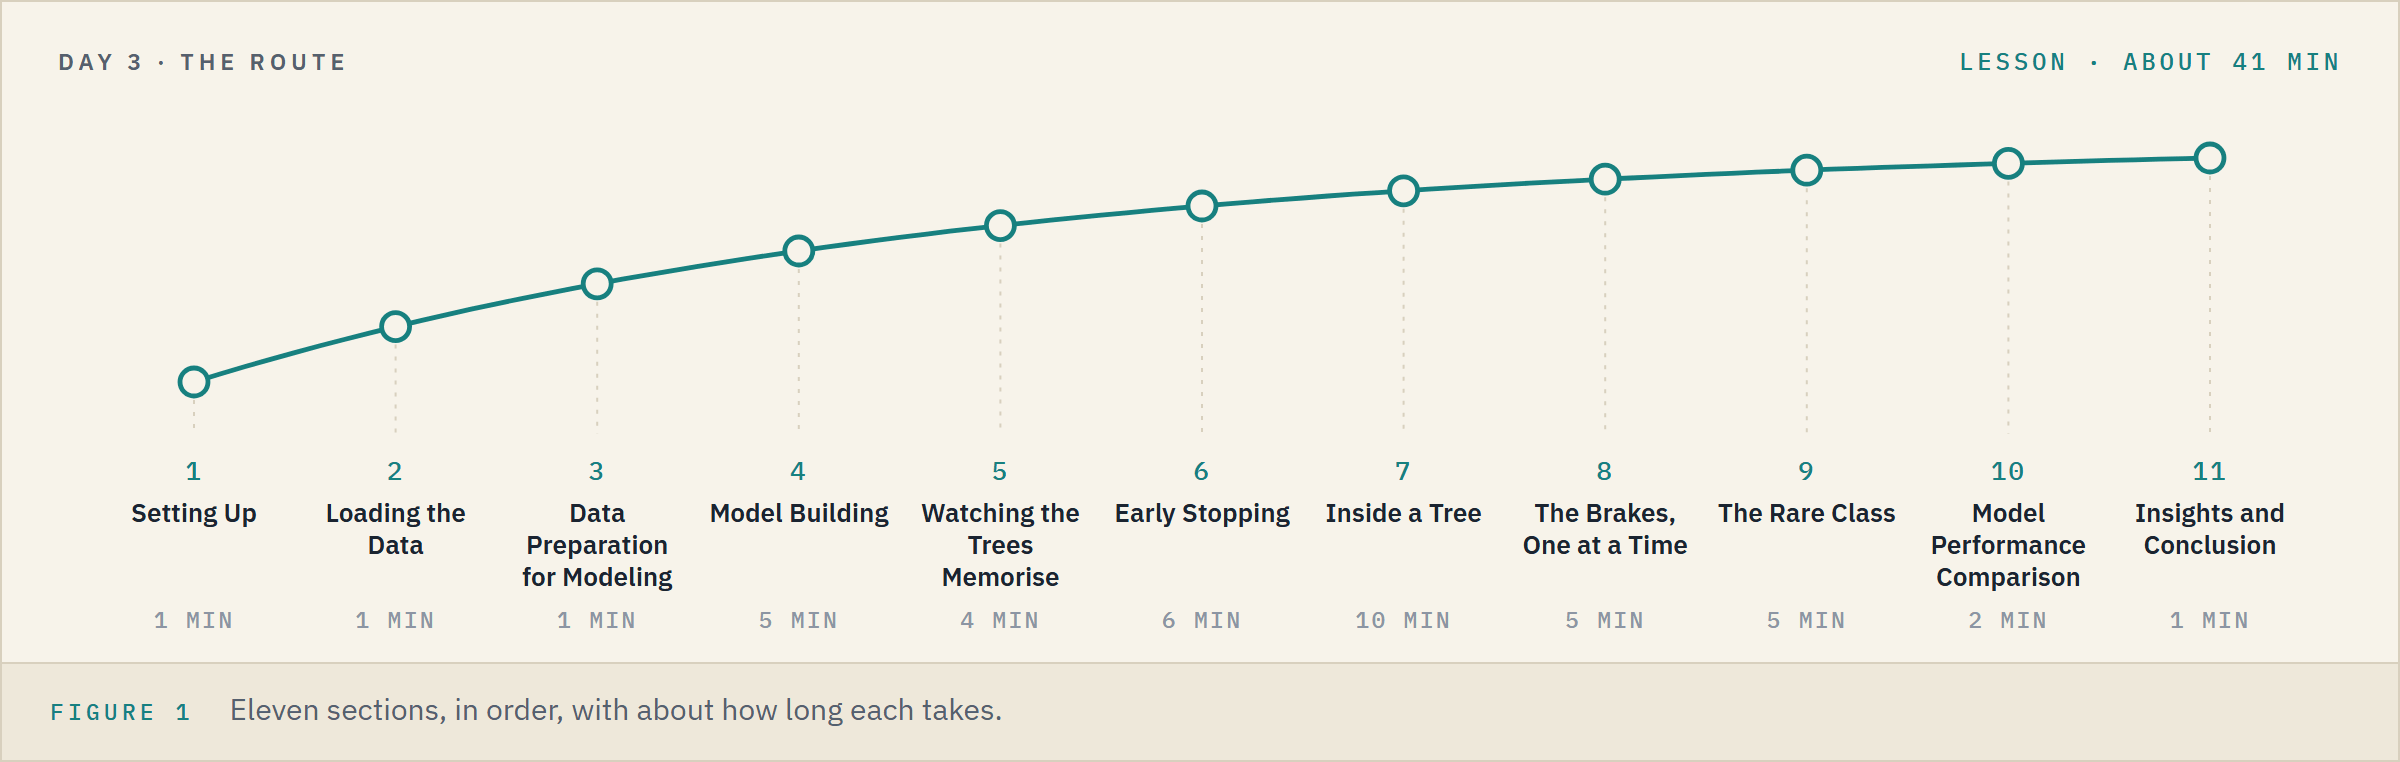

**Time.** About 41 minutes for the lesson, then about 12 for the four exercises.

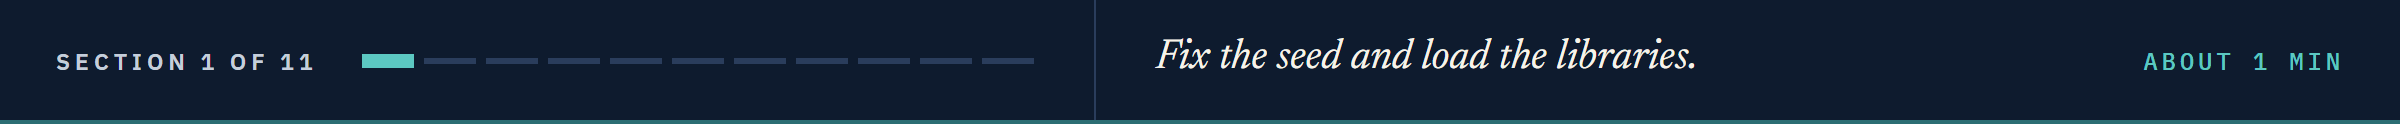

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a dropdown
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split the accounts, and to fold the training rows
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

# the course's earlier models: Course 4's logistic regression and tree, Days 3, 6 and 7's ensembles
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier

# today's model
from xgboost import XGBClassifier

# to score a model's outputs and its flags
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, accuracy_score, recall_score
from sklearn.metrics import precision_score, f1_score, confusion_matrix

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

# one colour for each of the four cells of a confusion matrix, as in Course 4's Day 7
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}

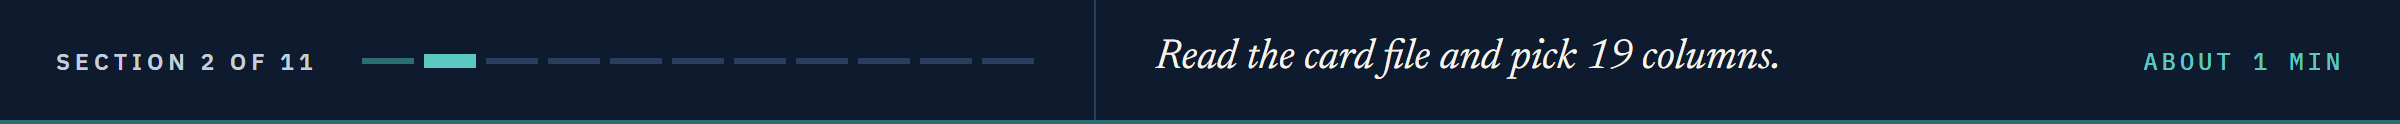

# Loading the Data

## Reading the Card File

In [3]:
# the 30,000 accounts; the target's name has spaces, so we keep it in a variable
card = pd.read_csv(DATA + "credit_card_default.csv")
TARGET = "default payment next month"

# every column except the ID, the four person columns and the target
X = card.drop(columns=["ID", "SEX", "EDUCATION", "MARRIAGE", "AGE", TARGET])
y = card[TARGET]
FEATURES = list(X.columns)
print(len(FEATURES), "features")

19 features


## Checking the Shape and the Default Share

In [4]:
# rows and columns, and how many accounts defaulted
print(card.shape)
print("Defaults:", y.sum(), " Share:", round(y.mean() * 100, 2), "percent")

(30000, 25)
Defaults: 6636  Share: 22.12 percent


**The file Course 4 used, unchanged, so we rebuild its rows exactly.**

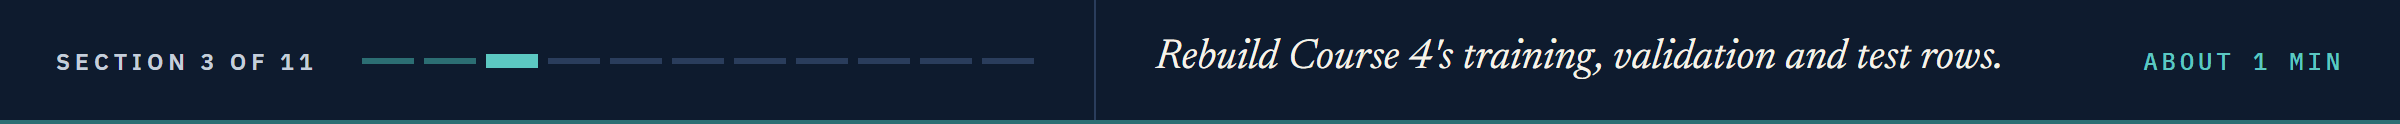

# Data Preparation for Modeling

## Course 4's Split

In [5]:
# Course 4's split: a fifth of the accounts to test, then a quarter of the rest to validation, defaults spread evenly
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=SEED)
print("Training:", len(X_train), " Validation:", len(X_valid), " Test:", len(X_test))
print("Default share:", round(y_train.mean(), 4), round(y_valid.mean(), 4), round(y_test.mean(), 4))

Training: 18000  Validation: 6000  Test: 6000
Default share: 0.2212 0.2212 0.2212


The same accounts as Course 4 and week 1, each set with the same default share.

Every score below is on the validation rows; Course 5 chooses nothing on them and never scores the test rows.

**Training rows fit, validation rows report, test rows stay closed.**

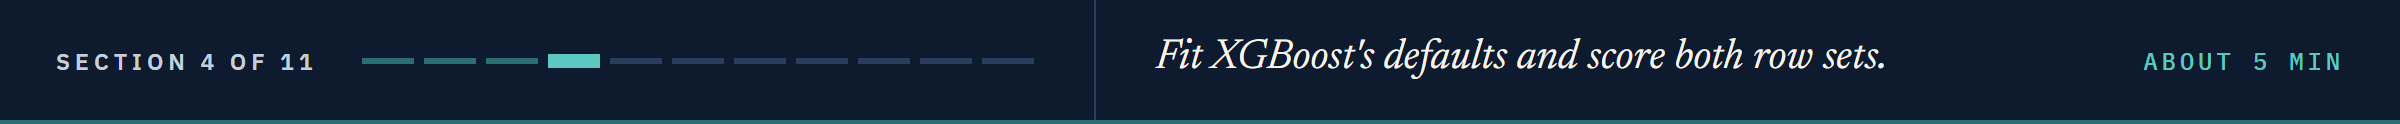

# Model Building

## XGBoost in Three Lines

**XGBoost** is Day 7's gradient boosting run on the log-odds of default, Course 4's Day 6 scale.
Every account starts at the training default rate, each tree is fitted to what the trees before it still miss, and a step of it is added.
It also puts a penalty on every leaf, so a leaf built on few accounts moves them less.
With row sampling switched on, a run on several threads can print different numbers from a run on one, so the course writes `n_jobs=1` on every XGBoost model.

> STORY: Tianqi Chen and Carlos Guestrin's paper "XGBoost: A Scalable Tree Boosting System" appeared in the Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, pages 785 to 794, in August 2016; its title carries the library's name. Source: https://api.crossref.org/works/10.1145/2939672.2939785

In [6]:
# XGBoost with its own defaults, on one thread, with the seed
xgb = XGBClassifier(n_jobs=1, random_state=SEED).fit(X_train, y_train)

## The Settings It Chose

In [7]:
# the settings we left alone: XGBoost keeps None here and applies its own defaults when it fits
params = xgb.get_params()
print({name: params[name] for name in ["n_estimators", "learning_rate", "max_depth", "reg_lambda"]})

{'n_estimators': None, 'learning_rate': None, 'max_depth': None, 'reg_lambda': None}


`None` means XGBoost's own default: 100 trees, a learning rate of 0.3, trees six questions deep, and `reg_lambda`, the leaf penalty, at 1.

Day 7's library took steps of 0.1 with trees three deep.

`.get_booster()` hands back the XGBoost model inside, and its `.trees_to_dataframe()` lists every node of every tree, one row each.
A leaf's `Feature` is `"Leaf"`.

In [8]:
# every node of the 100 trees, then the number of leaves in each tree
nodes = xgb.get_booster().trees_to_dataframe()
leaves = nodes[nodes["Feature"] == "Leaf"].groupby("Tree").size()
print("Trees:", len(leaves), " Leaves per tree: mean", round(leaves.mean(), 1), " fewest", leaves.min(), " most", leaves.max())

Trees: 100  Leaves per tree: mean 42.3  fewest 12  most 63


Six questions deep allows 64 leaves, and these trees use up to 63; Day 7's depth-3 trees had at most 8.

## Scoring on Training and Validation Rows

`model_performance_classification` is Course 4's Day 8's, with ROC AUC first, repeated as one cell.

In [9]:
# flag at or above the threshold, then the ROC AUC and four measures of the flags in one row
def model_performance_classification(model, predictors, target, threshold=0.5):
    flags = (model.predict_proba(predictors)[:, 1] >= threshold).astype(int)
    return pd.DataFrame({
        "ROC AUC": [roc_auc_score(target, model.predict_proba(predictors)[:, 1])],
        "Accuracy": [accuracy_score(target, flags)],
        "Recall": [recall_score(target, flags, zero_division=0)],
        "Precision": [precision_score(target, flags, zero_division=0)],
        "F1": [f1_score(target, flags, zero_division=0)],
    })

In [10]:
# the defaults on the accounts they were fitted on, and on the validation accounts, at 0.5
train_valid = pd.concat([model_performance_classification(xgb, X_train, y_train).T,
                         model_performance_classification(xgb, X_valid, y_valid).T], axis=1)
train_valid.columns = ["training", "validation"]
train_valid

,training,validation
ROC AUC,0.9550,0.7592
Accuracy,0.9014,0.8120
Recall,0.6090,0.3602
Precision,0.9179,0.6314
F1,0.7322,0.4587


### Interpretation of the Scores

ROC AUC is 0.9550 on the training rows and 0.7592 on the validation rows, a gap of 0.196.

Recall at 0.5 falls from 0.6090 to 0.3602.

Course 4's Day 9 read the same kind of gap in a full tree: the model remembers its own accounts.

**The defaults memorise the training accounts. Next we find the tree where that starts.**

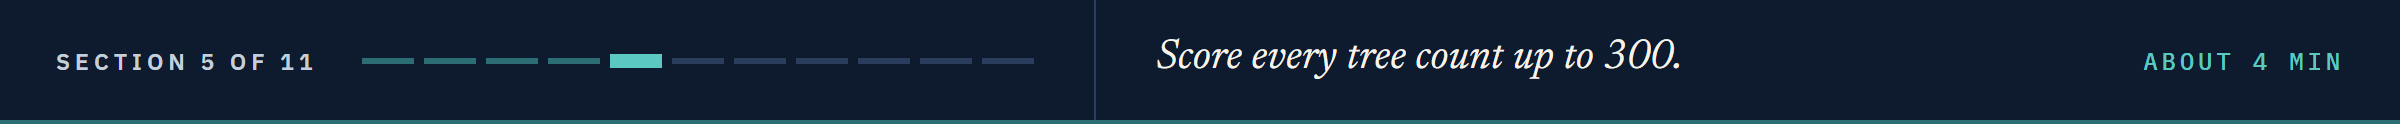

# Watching the Trees Memorise

`predict_proba(rows, iteration_range=(0, k))` scores the rows with the first k trees only, so one model of 300 trees gives the scores of 300 models.

**Predict 1**

Q. Sketch ROC AUC on the training rows and on the validation rows against the number of trees, from 1 to 300.

## Scores Tree by Tree

In [11]:
# the same defaults, grown to 300 trees
xgb300 = XGBClassifier(n_estimators=300, n_jobs=1, random_state=SEED).fit(X_train, y_train)

# ROC AUC and log loss from the first k trees, on both row sets, for k = 1 to 300
rows = []
for k in range(1, 301):
    train_out = xgb300.predict_proba(X_train, iteration_range=(0, k))[:, 1]
    valid_out = xgb300.predict_proba(X_valid, iteration_range=(0, k))[:, 1]
    rows.append([roc_auc_score(y_train, train_out), roc_auc_score(y_valid, valid_out), log_loss(y_train, train_out), log_loss(y_valid, valid_out)])
by_tree = pd.DataFrame(rows, columns=["training AUC", "validation AUC", "training log loss", "validation log loss"], index=range(1, 301))

In [12]:
# four tree counts, then the count with the best validation score on each measure
print(by_tree.loc[[1, 10, 100, 300]])
print("Highest validation ROC AUC:", round(by_tree["validation AUC"].max(), 4), "at", by_tree["validation AUC"].idxmax(), "trees")
print("Lowest validation log loss:", round(by_tree["validation log loss"].min(), 4), "at", by_tree["validation log loss"].idxmin(), "trees")

     training AUC  validation AUC  training log loss  validation log loss
1          0.7779          0.7516             0.4700               0.4772
10         0.8301          0.7726             0.3910               0.4355
100        0.9550          0.7592             0.2563               0.4635
300        0.9973          0.7492             0.1252               0.5249
Highest validation ROC AUC: 0.773 at 9 trees
Lowest validation log loss: 0.4352 at 9 trees


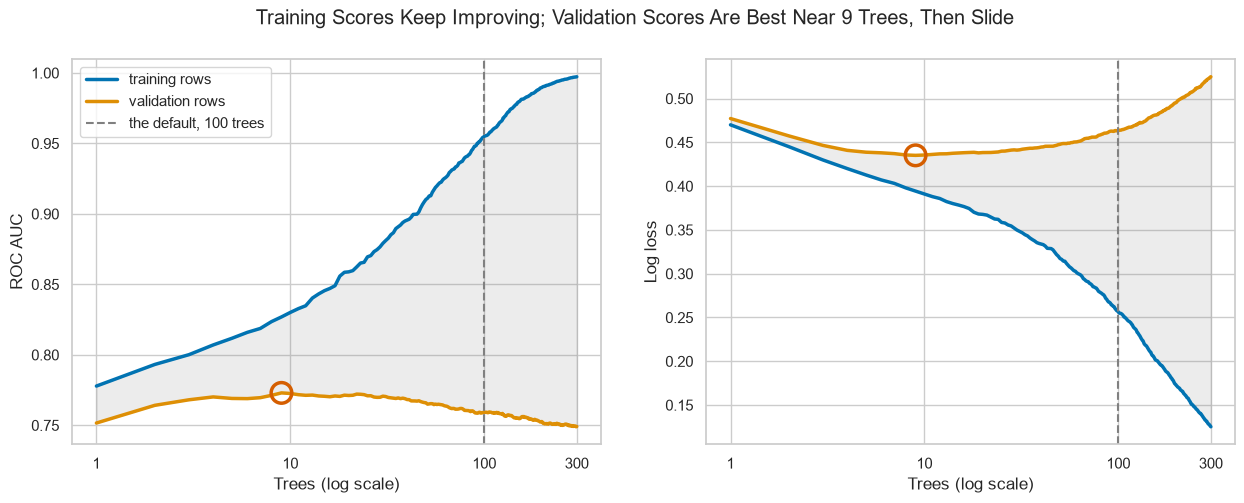

In [13]:
# ROC AUC (left) and log loss (right) by trees, on a log axis, the gap shaded and the best validation point ringed
fig, (auc_ax, loss_ax) = plt.subplots(1, 2, figsize=(15, 5))
for ax, measure in [(auc_ax, "AUC"), (loss_ax, "log loss")]:
    valid = by_tree["validation " + measure]
    best = valid.idxmax() if measure == "AUC" else valid.idxmin()
    ax.plot(by_tree.index, by_tree["training " + measure], linewidth=2.5, label="training rows")
    ax.plot(by_tree.index, valid, linewidth=2.5, label="validation rows")
    ax.fill_between(by_tree.index, by_tree["training " + measure], valid, color="gray", alpha=0.15)
    ax.scatter(best, valid[best], s=220, facecolor="none", edgecolor="C3", linewidth=2.5, zorder=3)
    ax.axvline(100, color="gray", linestyle="--", label="the default, 100 trees")
    ax.set(xscale="log", xticks=[1, 10, 100, 300], xticklabels=["1", "10", "100", "300"], xlabel="Trees (log scale)",
           ylabel=measure.replace("AUC", "ROC AUC").replace("log loss", "Log loss"))
auc_ax.legend(loc="upper left")
fig.suptitle("Training Scores Keep Improving; Validation Scores Are Best Near 9 Trees, Then Slide")
plt.show()

Training ROC AUC climbs from 0.7779 at one tree to 0.9550 at 100 and 0.9973 at 300.

Validation ROC AUC peaks at 9 trees, 0.773, then slides to 0.7492 by 300.

Validation log loss (Course 4's Day 6) is lowest at the same 9 trees, 0.4352, and climbs to 0.5249.

## Where the Outputs Go

In [14]:
# the share of defaulted accounts that the first 10, 100 and 300 trees put at 0.5 or more
caught = {}
for k in [10, 100, 300]:
    train_out = xgb300.predict_proba(X_train, iteration_range=(0, k))[:, 1]
    valid_out = xgb300.predict_proba(X_valid, iteration_range=(0, k))[:, 1]
    caught[k] = [(train_out[y_train == 1] >= 0.5).mean(), (valid_out[y_valid == 1] >= 0.5).mean()]
pd.DataFrame(caught, index=["training", "validation"])

,10,100,300
training,0.4016,0.6090,0.8764
validation,0.3497,0.3602,0.3617


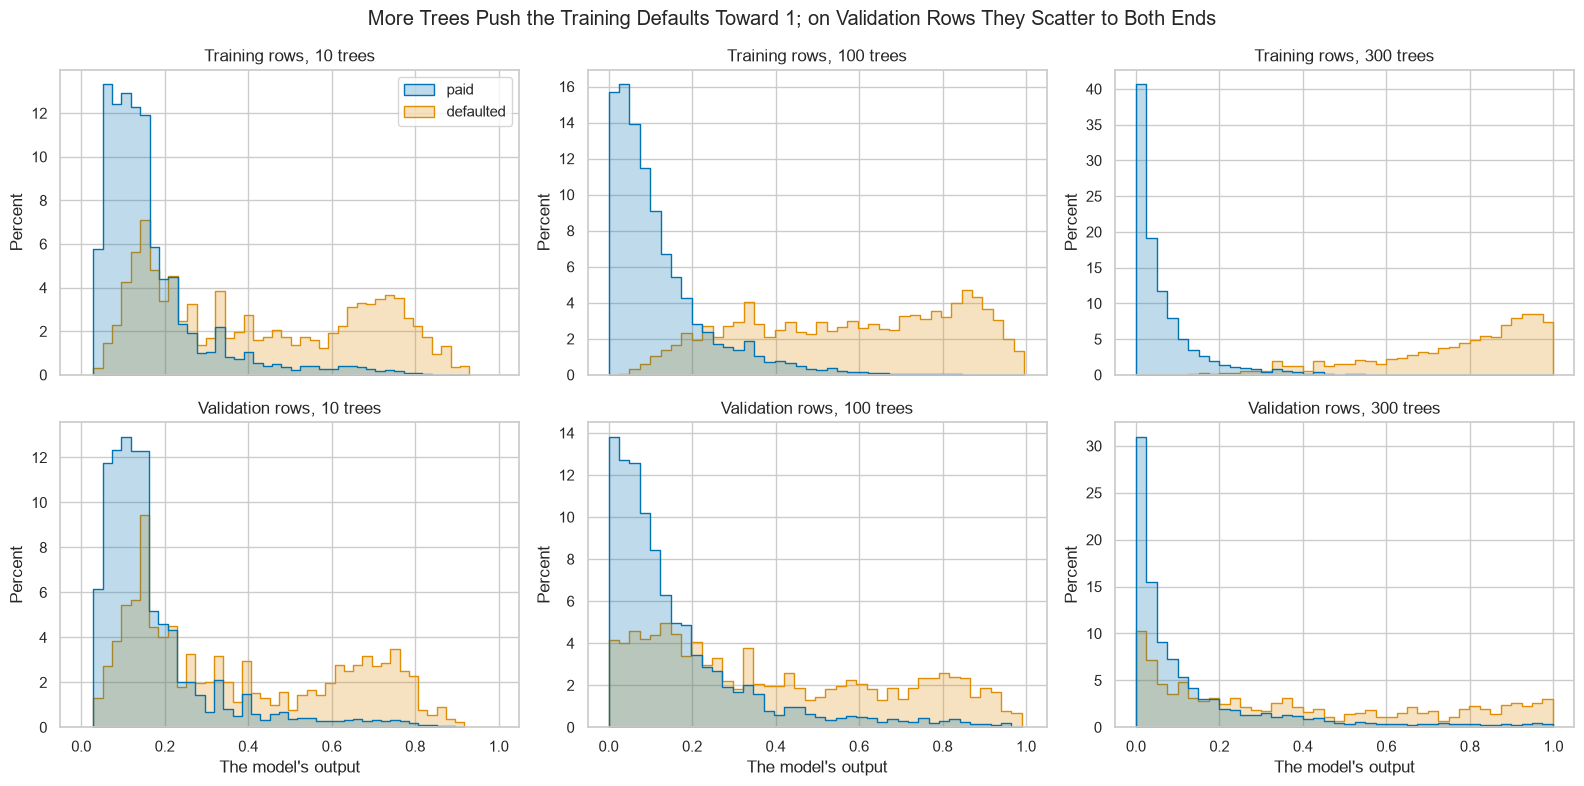

In [15]:
# the outputs by outcome after 10, 100 and 300 trees: training rows above, validation rows below
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
for column, k in enumerate([10, 100, 300]):
    for row, (rows, target, name) in enumerate([(X_train, y_train, "Training"), (X_valid, y_valid, "Validation")]):
        out = xgb300.predict_proba(rows, iteration_range=(0, k))[:, 1]
        sns.histplot(x=out, hue=target.map({0: "paid", 1: "defaulted"}).values, hue_order=["paid", "defaulted"], bins=40,
                     stat="percent", common_norm=False, element="step", legend=(row + column == 0), ax=axes[row, column])
        axes[row, column].set(title=f"{name} rows, {k} trees", xlabel="The model's output")
fig.suptitle("More Trees Push the Training Defaults Toward 1; on Validation Rows They Scatter to Both Ends")
plt.tight_layout()
plt.show()

At 10, 100 and 300 trees the model puts 40, 61 and 88 percent of the training defaults at 0.5 or more.

On the validation rows the share holds at 35 to 36 percent: what the extra trees learn belongs to the training accounts.

**The validation line peaks at 9 trees, but validation rows only report: choosing the count from this chart would choose on them. The count needs rows of its own inside the training rows.**

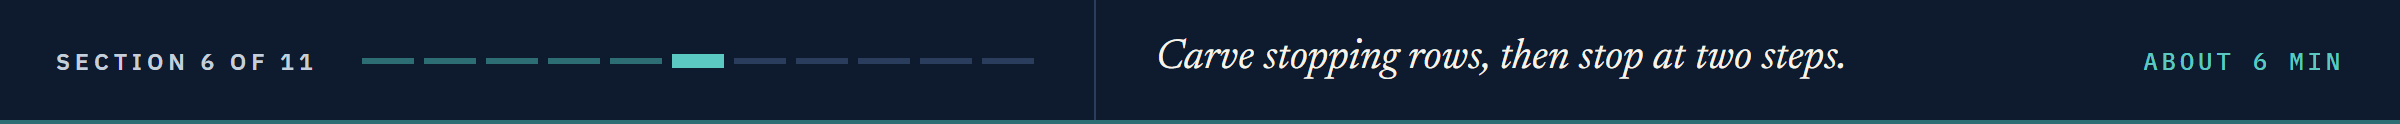

# Early Stopping

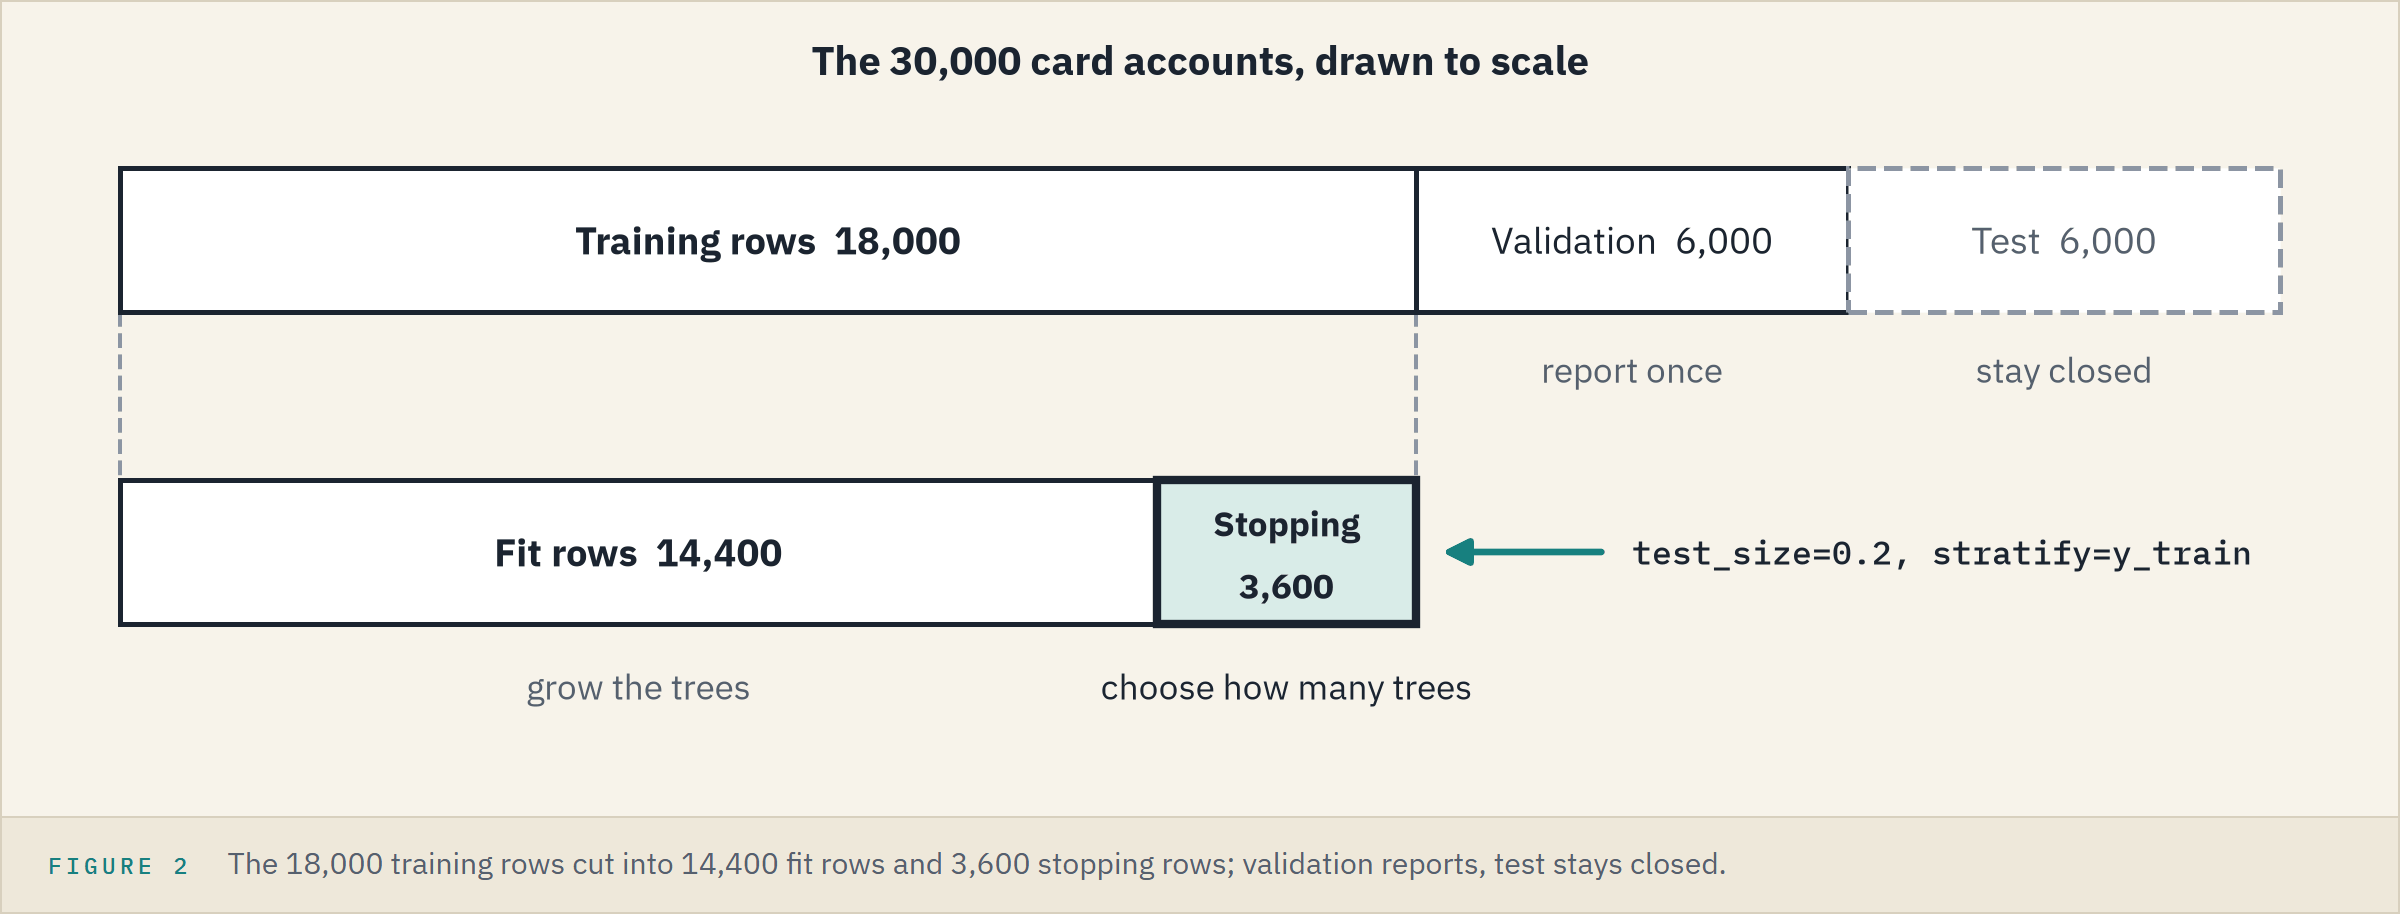

**Early stopping** grows trees one at a time and stops once a score on rows the trees never fit stops improving.
Those rows are the **stopping rows**, cut from the training rows, so the validation rows only report.

## Carving the Stopping Rows

In [16]:
# a fifth of the training rows held back to stop on, defaults spread evenly; the rest fit the trees
X_fit, X_stop, y_fit, y_stop = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
print("Fit rows:", len(X_fit), " Stopping rows:", len(X_stop), " Default share:", round(y_fit.mean(), 4), round(y_stop.mean(), 4))

# Index.intersection (Course 3's) lists the account labels two row sets share
print("Stopping rows that are also validation rows:", len(X_stop.index.intersection(X_valid.index)))

Fit rows: 14400  Stopping rows: 3600  Default share: 0.2212 0.2211
Stopping rows that are also validation rows: 0


No stopping row is a validation row: stopping on the validation rows would let the rows that report choose the count.

## Stopping at the Defaults' Step

Three settings in the constructor switch it on:

* `n_estimators=1000`, a ceiling the stop should never reach
* `eval_metric="logloss"`, the score watched
* `early_stopping_rounds=50`, the **patience**: rounds without a new lowest score before the stop

`fit(..., eval_set=[...], verbose=False)` scores pairs of rows after every round, quietly: the fit rows first, to draw their curve, and the stopping rows last, because XGBoost stops on the last pair.
`.evals_result()` then holds each pair's log loss by round, `"validation_0"` and `"validation_1"`.
`.best_iteration` counts from 0, so the trees kept are one more; `.best_score` is the lowest stopping log loss.

In [17]:
# up to 1,000 trees at the default step of 0.3, stopped on the stopping rows
stop_03 = XGBClassifier(n_estimators=1000, eval_metric="logloss", early_stopping_rounds=50, n_jobs=1, random_state=SEED)
stop_03.fit(X_fit, y_fit, eval_set=[(X_fit, y_fit), (X_stop, y_stop)], verbose=False)

# the stopping rows' log loss by round, the trees kept and the rounds run before the stop
stop_loss_03 = stop_03.evals_result()["validation_1"]["logloss"]
print("Trees kept:", stop_03.best_iteration + 1, " Rounds run:", len(stop_loss_03))
print("Stopping log loss: round 1", round(stop_loss_03[0], 4), " lowest", round(stop_03.best_score, 4), " last", round(stop_loss_03[-1], 4))

Trees kept: 9  Rounds run: 59
Stopping log loss: round 1 0.476  lowest 0.4381  last 0.4595


The stopping log loss is lowest after 9 trees; 50 rounds pass without a lower one, and the fit stops at 59.

From here on `predict_proba` uses the 9 trees kept.

**Predict 2**

On Day 7's bonds, a third of the step needed about three times the rounds.

Q. At a learning rate of 0.05, a sixth of the default step, how many trees will the stopping rows keep? Write down a number.

## Stopping at a Smaller Step

In [18]:
# the same stop at a learning rate of 0.05
stop_005 = XGBClassifier(n_estimators=1000, learning_rate=0.05, eval_metric="logloss", early_stopping_rounds=50, n_jobs=1,
                         random_state=SEED)
stop_005.fit(X_fit, y_fit, eval_set=[(X_fit, y_fit), (X_stop, y_stop)], verbose=False)
stop_loss_005 = stop_005.evals_result()["validation_1"]["logloss"]
print("Trees kept:", stop_005.best_iteration + 1, " Rounds run:", len(stop_loss_005), " Lowest:", round(stop_005.best_score, 4))

Trees kept: 61  Rounds run: 111  Lowest: 0.436


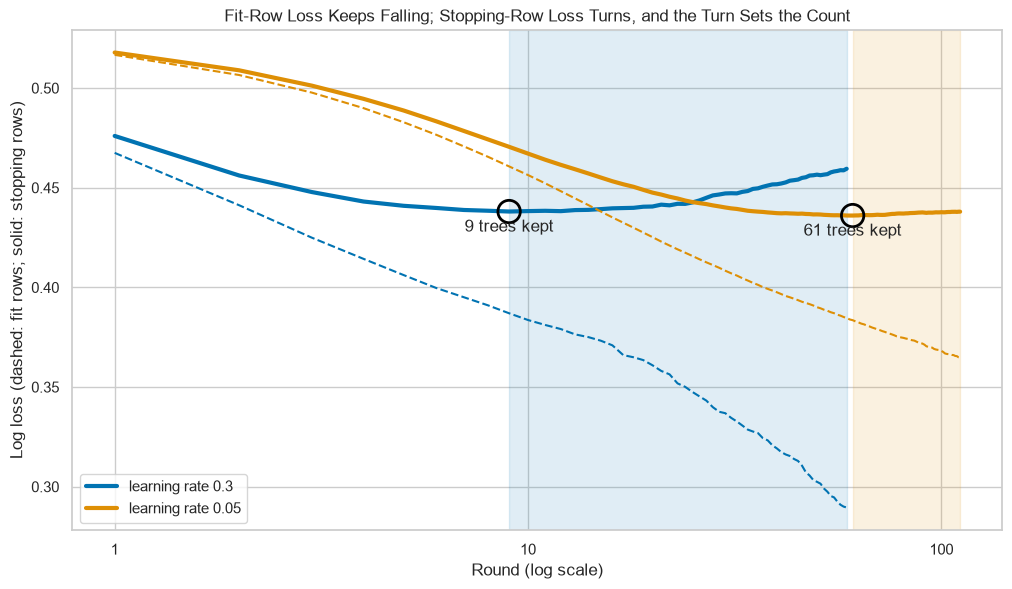

In [19]:
# both runs: fit-row (dashed) and stopping-row (solid) log loss by round, the best round ringed, the 50 patience rounds shaded
fig, ax = plt.subplots(figsize=(12, 6.5))
for model, colour, step in [(stop_03, "C0", 0.3), (stop_005, "C1", 0.05)]:
    history = model.evals_result()
    rounds = np.arange(1, len(history["validation_1"]["logloss"]) + 1)
    best = model.best_iteration + 1
    ax.plot(rounds, history["validation_0"]["logloss"], color=colour, linewidth=1.5, linestyle="--")
    ax.plot(rounds, history["validation_1"]["logloss"], color=colour, linewidth=3, label=f"learning rate {step}")
    ax.axvspan(best, rounds[-1], color=colour, alpha=0.12)
    ax.scatter(best, model.best_score, s=260, facecolor="none", edgecolor="black", linewidth=2, zorder=3)
    ax.text(best, model.best_score - 0.004, f"{best} trees kept", ha="center", va="top", fontsize=12)
ax.set(xscale="log", xticks=[1, 10, 100], xticklabels=["1", "10", "100"], xlabel="Round (log scale)",
       ylabel="Log loss (dashed: fit rows; solid: stopping rows)")
ax.set_title("Fit-Row Loss Keeps Falling; Stopping-Row Loss Turns, and the Turn Sets the Count")
ax.legend(loc="lower left")
plt.show()

### Interpretation of the Stopping Curve

The fit-row loss falls every round: the trees always fit their own rows better.

The stopping-row loss falls, turns and climbs; the count is the turn, and the shaded patience rounds are thrown away.

A sixth of the step keeps 61 trees instead of 9 and reaches a slightly lower loss, 0.436 against 0.4381.

## Scoring the Stopped Models Once

In [20]:
# each stopped model on the rows that fit it, and once on the validation rows
stopped = pd.DataFrame({"trees": [m.best_iteration + 1 for m in (stop_03, stop_005)],
                        "fit-row ROC AUC": [roc_auc_score(y_fit, m.predict_proba(X_fit)[:, 1]) for m in (stop_03, stop_005)],
                        "validation ROC AUC": [roc_auc_score(y_valid, m.predict_proba(X_valid)[:, 1]) for m in (stop_03, stop_005)],
                        "validation AP": [average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1]) for m in (stop_03, stop_005)]},
                       index=["learning rate 0.3", "learning rate 0.05"])
stopped

,trees,fit-row ROC AUC,validation ROC AUC,validation AP
learning rate 0.3,9,0.8356,0.7705,0.5447
learning rate 0.05,61,0.8432,0.7767,0.5463


Validation ROC AUC 0.7705 and 0.7767, against 0.7592 for the defaults' 100 trees.

On their own fit rows they score 0.8356 and 0.8432, far below the defaults' 0.9550: much less is memorised.

**The stopping rows chose the count and the validation rows only reported: 0.7592 became 0.7767. A smaller step helped; inside a tree sit the other brakes.**

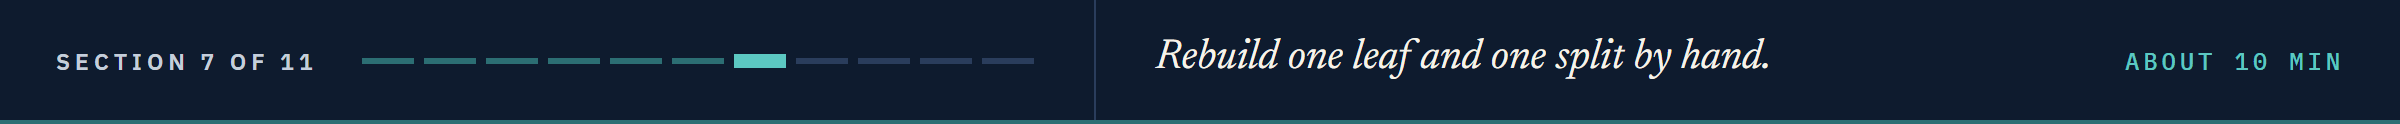

# Inside a Tree

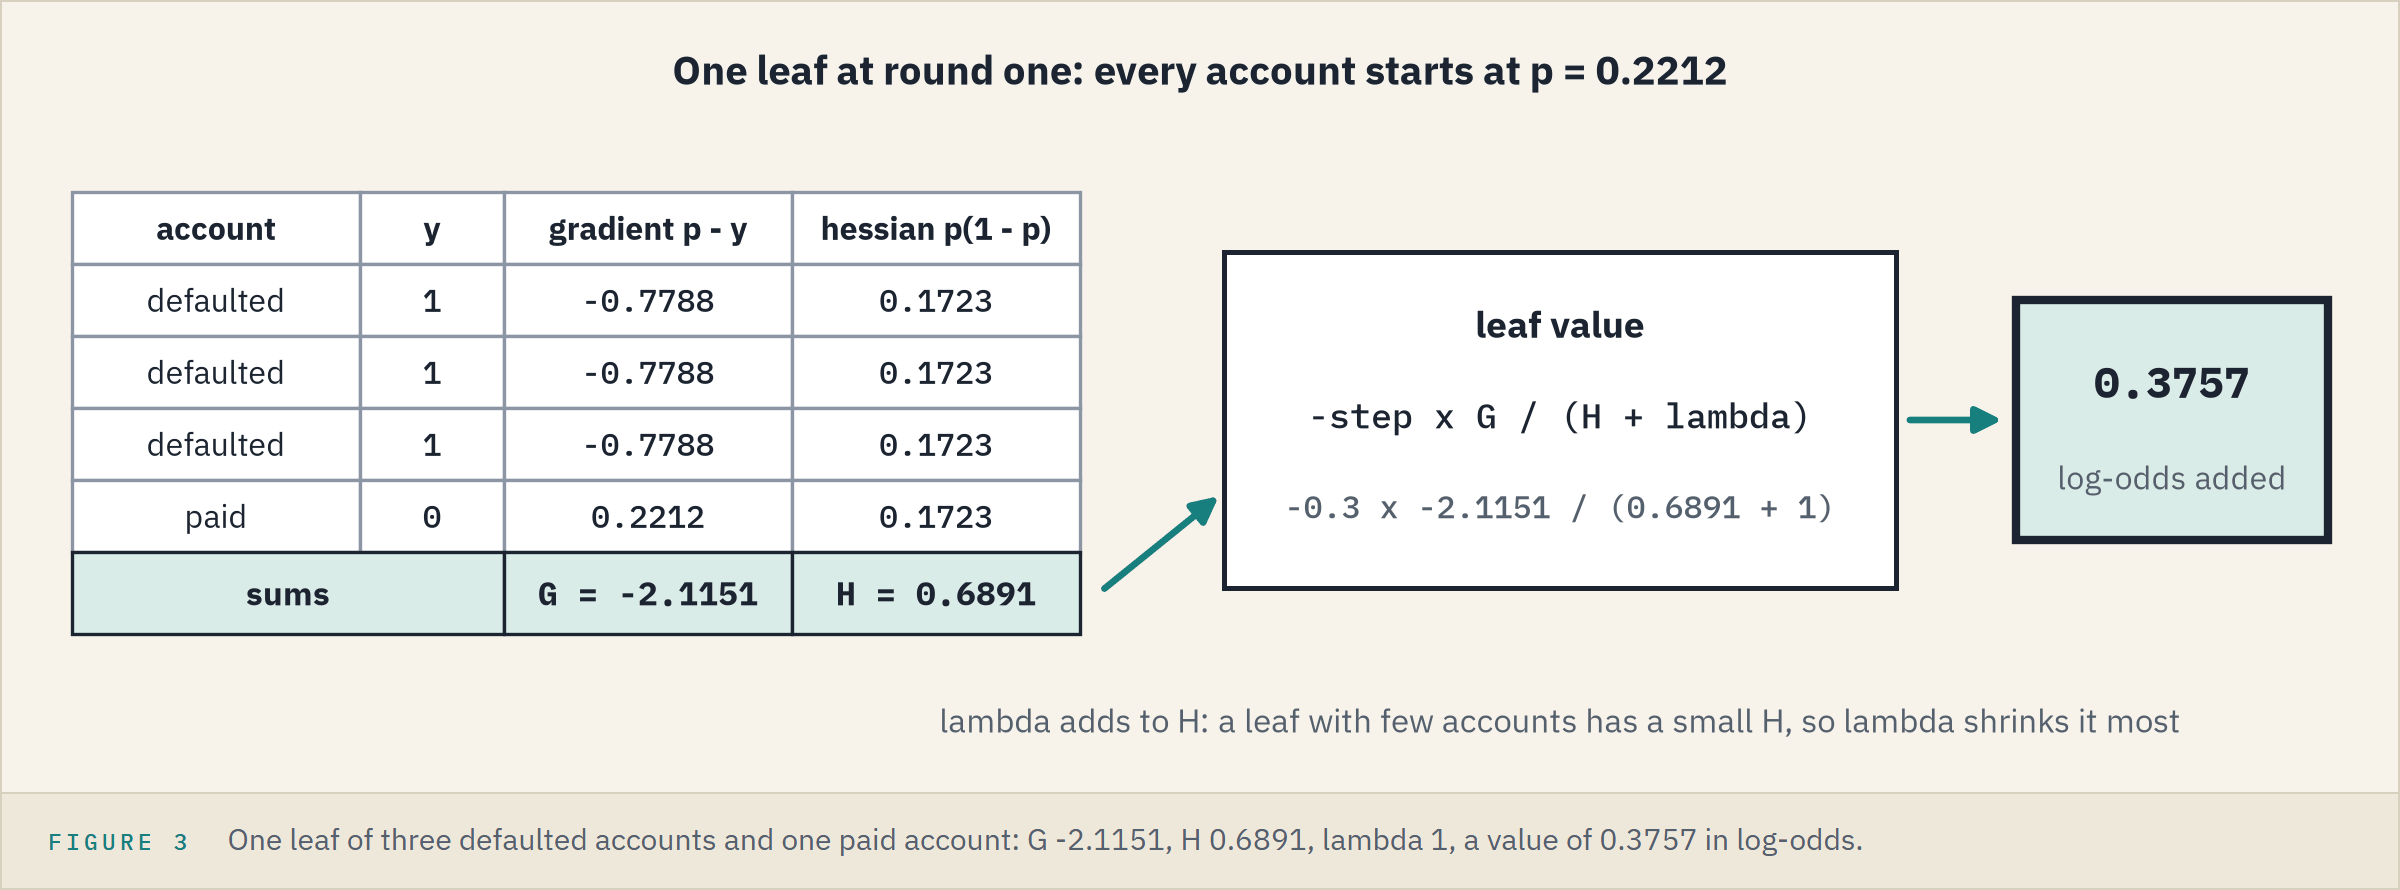

Course 4's Day 6 scored an output p against an outcome y with log loss.
On the log-odds, each account's **gradient** is p - y, the slope of its log loss, and its **hessian** is p(1 - p), its curvature.
A leaf's value is -step x G / (H + lambda), where G and H are the leaf's gradients and hessians summed and lambda is `reg_lambda`.

## Round One by Hand

In [21]:
# round zero: every account at the training default rate, also written as log-odds
start = y_train.mean()
print("Start:", round(start, 4), " Log-odds:", round(np.log(start / (1 - start)), 4))

# every account's gradient and hessian at the start
gradient = start - y_train
hessian = start * (1 - start)
print("Gradient, paid:", round(start, 4), " defaulted:", round(start - 1, 4), " Hessian, every account:", round(hessian, 4))

Start: 0.2212  Log-odds: -1.2586
Gradient, paid: 0.2212  defaulted: -0.7788  Hessian, every account: 0.1723


## The First Split

In [22]:
# one tree of one question at XGBoost's defaults, and its three nodes
stump = XGBClassifier(n_estimators=1, max_depth=1, n_jobs=1, random_state=SEED).fit(X_train, y_train)
stump_nodes = stump.get_booster().trees_to_dataframe()
stump_nodes[["ID", "Feature", "Split", "Gain", "Cover"]]

,ID,Feature,Split,Gain,Cover
0,0-0,PAY_0,2.0000,2809.1199,3101.0933
1,0-1,Leaf,<NA>,-0.0978,2776.3398
2,0-2,Leaf,<NA>,0.8334,324.7534


The root asks `PAY_0 < 2.0`, strictly less than, where scikit-learn's trees ask "less than or equal".

In a leaf's row `Gain` holds the leaf's value and `Cover` its H.

In [23]:
# G and H on each side of the question, then each leaf's value by hand, with the step 0.3 and lambda 1
left = X_train["PAY_0"] < 2.0
G_left, G_right = gradient[left].sum(), gradient[~left].sum()
H_left, H_right = hessian * left.sum(), hessian * (~left).sum()
print("Accounts:", left.sum(), (~left).sum(), " G:", round(G_left, 2), round(G_right, 2), " H:", round(H_left, 2), round(H_right, 2))
leaf_left, leaf_right = -0.3 * G_left / (H_left + 1), -0.3 * G_right / (H_right + 1)
print("Leaf values by hand:", round(leaf_left, 4), round(leaf_right, 4))

Accounts: 16115 1885  G: 905.0 -905.0  H: 2776.34 324.75
Leaf values by hand: -0.0978 0.8334


In [24]:
# each leaf's output after one tree, through Course 4's Day 6 logistic curve, beside the default rate inside it
start_log_odds = np.log(start / (1 - start))
print("Output after one tree:", round(1 / (1 + np.exp(-(start_log_odds + leaf_left))), 4),
      round(1 / (1 + np.exp(-(start_log_odds + leaf_right))), 4))
print("Default rate in each leaf:", round(y_train[left].mean(), 4), round(y_train[~left].mean(), 4))

Output after one tree: 0.2048 0.3953
Default rate in each leaf: 0.1651 0.7013


The hand values, -0.0978 and 0.8334, are the table's leaf values.

One tree moves the 1,885 accounts two or more months late from 0.2212 to 0.3953, though 0.7013 of them defaulted: each tree goes part of the way.

## What Lambda Does to a Leaf

A leaf holding n defaulted accounts and nothing else has G = n(p - 1) and H = n p(1 - p) at round one.
`np.logspace(0, 3, 200)` (Course 4's) spreads 200 leaf sizes from 1 to 1,000 evenly on a log scale.

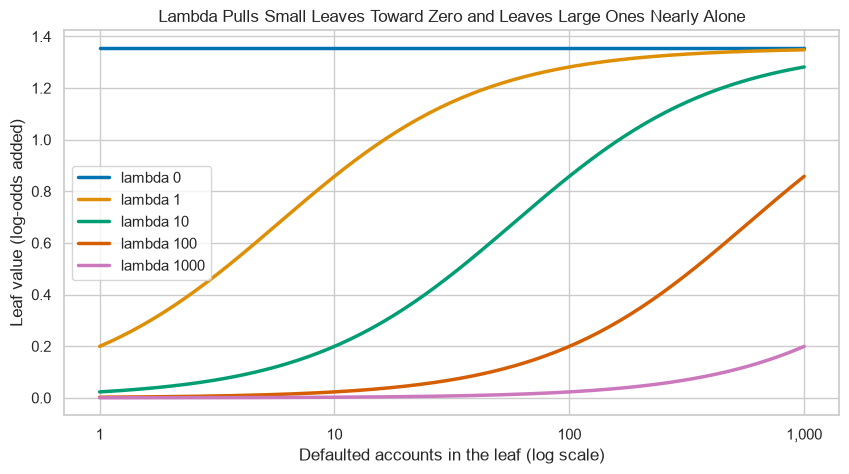

In [25]:
# the round-one value of a leaf of n defaulted accounts, for five values of lambda
sizes = np.logspace(0, 3, 200)
for lam in [0, 1, 10, 100, 1000]:
    plt.plot(sizes, -0.3 * sizes * (start - 1) / (sizes * hessian + lam), linewidth=2.5, label=f"lambda {lam}")
plt.xscale("log")
plt.xticks([1, 10, 100, 1000], ["1", "10", "100", "1,000"])
plt.xlabel("Defaulted accounts in the leaf (log scale)")
plt.ylabel("Leaf value (log-odds added)")
plt.title("Lambda Pulls Small Leaves Toward Zero and Leaves Large Ones Nearly Alone")
plt.legend()
plt.show()

In [26]:
# the same values at 1, 10 and 100 accounts
pd.DataFrame({lam: [-0.3 * n * (start - 1) / (n * hessian + lam) for n in [1, 10, 100]] for lam in [0, 1, 10, 100, 1000]},
             index=["1 account", "10 accounts", "100 accounts"])

,0,1,10,100,1000
1 account,1.3561,0.1993,0.0230,0.0023,0.0002
10 accounts,1.3561,0.8581,0.1993,0.0230,0.0023
100 accounts,1.3561,1.2817,0.8581,0.1993,0.0230


With no penalty the leaf adds 1.3561 whatever its size: one account moves as far as a hundred.

Lambda 1 cuts a one-account leaf to 0.1993, a ten-account leaf to 0.8581, and barely touches a hundred, 1.2817.

### Your Turn: Turn the Penalty

In [27]:
# the first tree of the defaults at eight values of lambda: each leaf's Cover and value
lambdas = [0, 1, 3, 10, 30, 100, 300, 1000]
first_leaves = {}
for lam in lambdas:
    lam_nodes = XGBClassifier(n_estimators=1, reg_lambda=lam, n_jobs=1, random_state=SEED).fit(X_train, y_train).get_booster().trees_to_dataframe()
    first_leaves[lam] = lam_nodes[lam_nodes["Feature"] == "Leaf"]

In [28]:
# one panel: each leaf of the first tree as a dot, its Cover across (log scale), its value up
def leaf_panel(lam, ax):
    table = first_leaves[lam]
    ax.scatter(table["Cover"], table["Gain"], s=70, alpha=0.7)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(xscale="log", xticks=[1, 10, 100, 1000], xticklabels=["1", "10", "100", "1,000"], ylim=(-0.5, 1.45),
           xlabel="Cover, the leaf's H (log scale)", ylabel="Leaf value (log-odds)")
    ax.set_title(f"lambda {lam}: {len(table)} leaves, largest value {table['Gain'].abs().max():.4f}")

Pick lambda and watch the small leaves on the left.

In [29]:
# your turn: pick lambda and watch the first tree's leaves
def show_leaves(lam=0):
    fig, ax = plt.subplots(figsize=(10, 5))
    leaf_panel(lam, ax)
    plt.show()

interact(show_leaves, lam=lambdas);

interactive(children=(Dropdown(description='lam', options=(0, 1, 3, 10, 30, 100, 300, 1000), value=0), Output(…

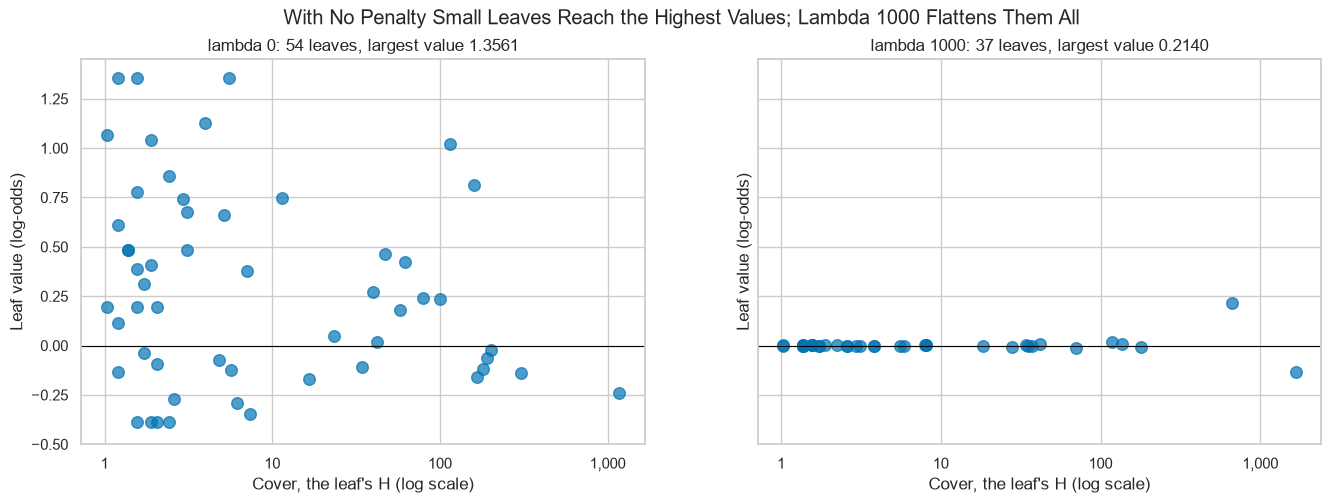

In [30]:
# the dropdown's starting value beside lambda 1000, drawn as a still picture (dropdowns do not run on GitHub)
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
leaf_panel(0, axes[0])
leaf_panel(1000, axes[1])
fig.suptitle("With No Penalty Small Leaves Reach the Highest Values; Lambda 1000 Flattens Them All")
plt.show()

At lambda 0 three leaves of defaulted accounts alone reach the most a leaf can add, 1.3561; at lambda 1000 the largest value is 0.2140.

`min_child_weight`, 1 by default, is a floor on Cover: at round one that is 6 accounts, since each adds 0.1723.

`reg_alpha` takes a fixed amount off G before the division, so a leaf whose G lies within that amount of zero is set to 0.

## Gain and Gamma

The **gain** of a split measures how far it lowers the loss: G_L^2 / (H_L + lambda) + G_R^2 / (H_R + lambda) - (G_L + G_R)^2 / (H_L + H_R + lambda), with L and R the two sides.
`gamma` is the least gain a split must reach: a question that gains less is not kept.

In [31]:
# the gain of the first question by hand, beside the table's
gain = G_left ** 2 / (H_left + 1) + G_right ** 2 / (H_right + 1) - (G_left + G_right) ** 2 / (H_left + H_right + 1)
print("Gain by hand:", round(gain, 1), " In the table:", round(stump_nodes.loc[0, "Gain"], 1))

# the first tree of the defaults: its questions ranked by gain
first_tree = nodes[(nodes["Tree"] == 0) & (nodes["Feature"] != "Leaf")].sort_values("Gain", ascending=False)
print("Questions:", len(first_tree), " Median gain:", round(first_tree["Gain"].median(), 2), " Below 5:", (first_tree["Gain"] < 5).sum())

Gain by hand: 2809.1  In the table: 2809.1
Questions: 50  Median gain: 9.03  Below 5: 18


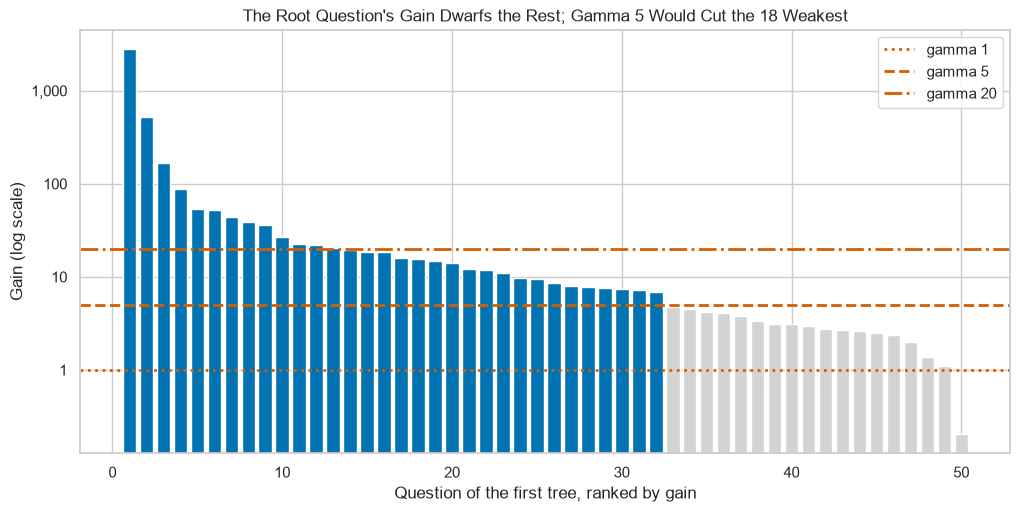

In [32]:
# the gain ladder: every question of the first tree by gain (log scale), the ones below gamma 5 faded
fig, ax = plt.subplots(figsize=(12, 5.5))
ranks = np.arange(1, len(first_tree) + 1)
ax.bar(ranks, first_tree["Gain"], color=["C0" if g >= 5 else "lightgray" for g in first_tree["Gain"]])
for gamma, style in [(1, ":"), (5, "--"), (20, "-.")]:
    ax.axhline(gamma, color="C3", linestyle=style, linewidth=2, label=f"gamma {gamma}")
ax.set(yscale="log", yticks=[1, 10, 100, 1000], yticklabels=["1", "10", "100", "1,000"],
       xlabel="Question of the first tree, ranked by gain", ylabel="Gain (log scale)")
ax.set_title("The Root Question's Gain Dwarfs the Rest; Gamma 5 Would Cut the 18 Weakest")
ax.legend()
plt.show()

In [33]:
# leaves left in the first tree at four values of gamma
for gamma in [0, 1, 5, 20]:
    gamma_nodes = XGBClassifier(n_estimators=1, gamma=gamma, n_jobs=1, random_state=SEED).fit(X_train, y_train).get_booster().trees_to_dataframe()
    print("gamma", gamma, ":", (gamma_nodes["Feature"] == "Leaf").sum(), "leaves")

gamma 0 : 51 leaves
gamma 1 : 50 leaves
gamma 5 : 33 leaves
gamma 20 : 14 leaves


The root's gain, 2,809.1 by hand and in the table, is hundreds of times the median question's, 9.03.

Gamma 5 removes the 18 questions below it and leaves 33 leaves; gamma 20 leaves 14.

**Lambda shrinks small leaves most, gamma removes weak questions, and `min_child_weight` keeps leaves from getting tiny. Folds inside the training rows tell us which brakes these accounts need.**

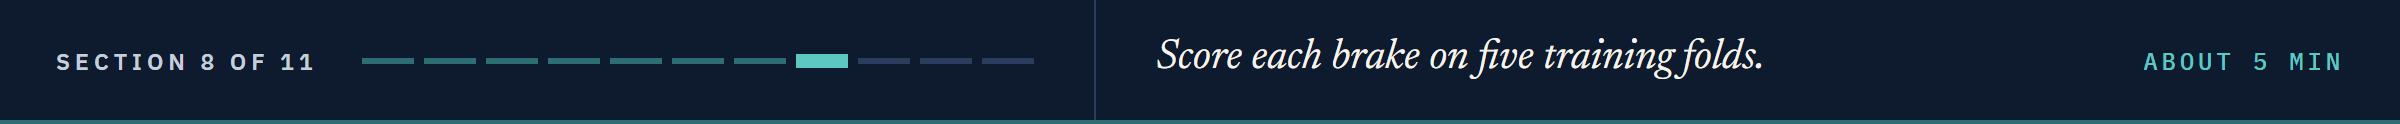

# The Brakes, One at a Time

## Five Folds Inside the Training Rows

Each brake is scored on Course 4's Day 9 stratified folds of the training rows with `cross_validate(..., return_train_score=True)` (Day 5's), which also scores the fitted folds.
Two brakes are new: `subsample`, the share of rows each tree draws without replacement, and `colsample_bytree`, the share of columns each tree may ask about.
`**{brake: value}` hands a dictionary to the model as settings, here one setting, `brake=value`.

In [34]:
# five folds of the training rows, defaults spread evenly, shuffled with the seed
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# each brake at a few values, every other setting at XGBoost's default: mean ROC AUC on the fitted and held-out folds
brakes = {"max_depth": [2, 4, 6, 10], "learning_rate": [0.05, 0.1, 0.3], "reg_lambda": [0, 1, 10, 100, 1000],
          "reg_alpha": [0, 10, 100], "gamma": [0, 1, 5, 10], "min_child_weight": [1, 20, 100],
          "subsample": [0.5, 0.8, 1.0], "colsample_bytree": [0.5, 0.8, 1.0]}
board = []
for brake, values in brakes.items():
    for value in values:
        result = cross_validate(XGBClassifier(n_jobs=1, random_state=SEED, **{brake: value}), X_train, y_train, cv=folds,
                                scoring="roc_auc", return_train_score=True, n_jobs=1)
        board.append([brake, value, result["train_score"].mean(), result["test_score"].mean()])
board = pd.DataFrame(board, columns=["brake", "value", "fitted folds", "held-out folds"])

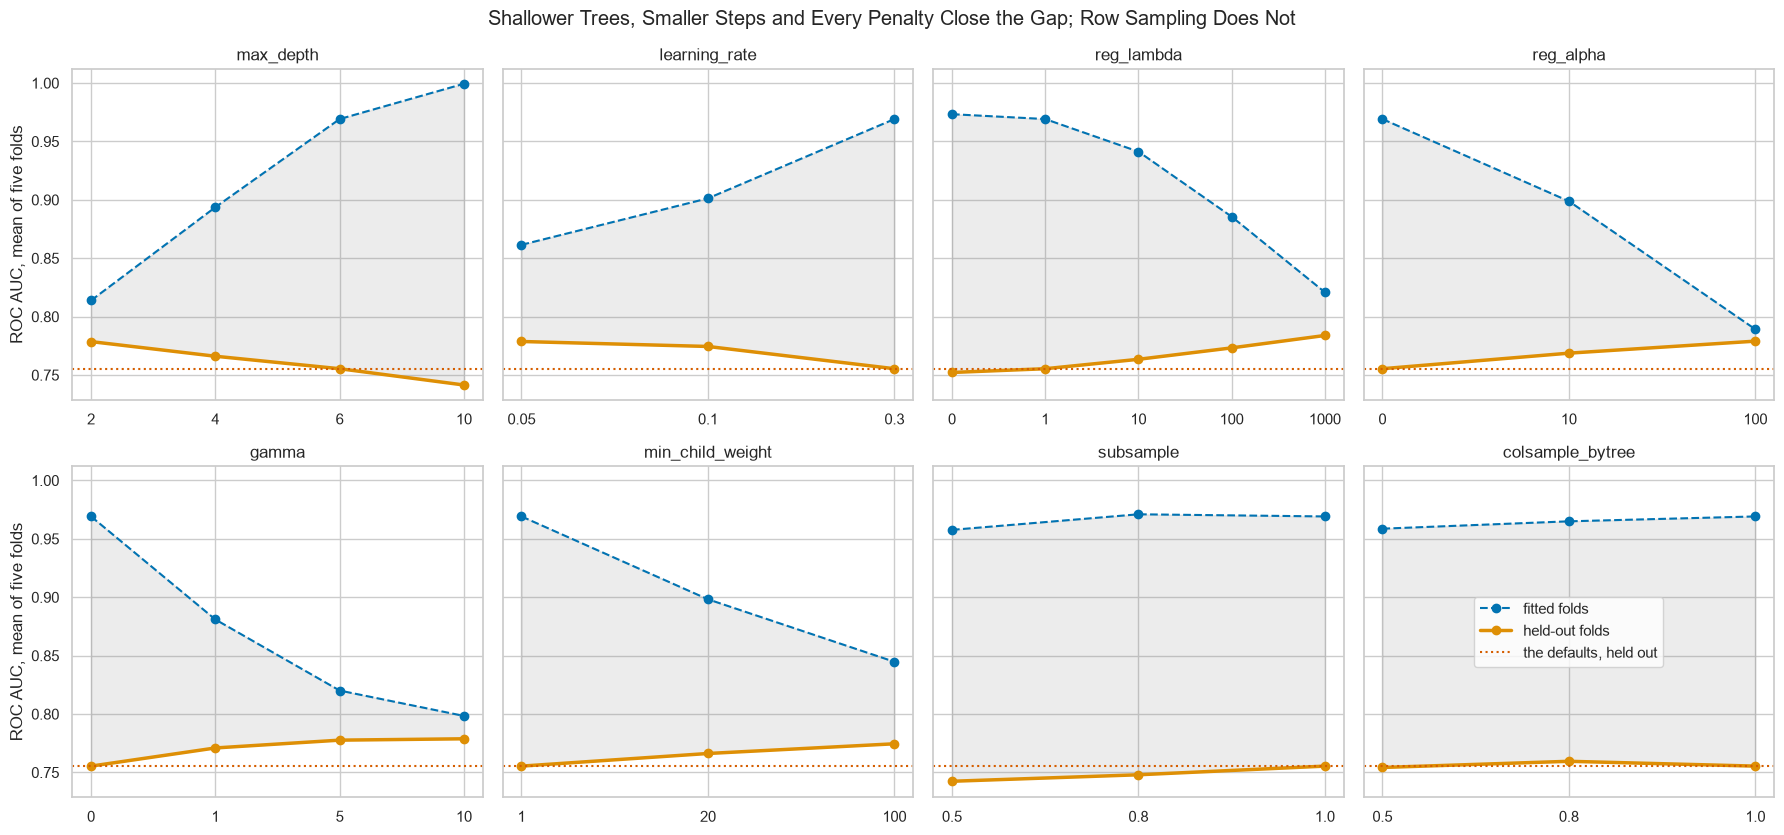

In [35]:
# one panel per brake: fitted (dashed) and held-out (solid) ROC AUC at each value, the gap shaded, the defaults dotted
defaults_held_out = board.loc[(board["brake"] == "max_depth") & (board["value"] == 6), "held-out folds"].iloc[0]
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5), sharey=True)
for ax, (brake, values) in zip(axes.ravel(), brakes.items()):
    one = board[board["brake"] == brake]
    ax.plot(range(len(values)), one["fitted folds"], marker="o", linestyle="--", label="fitted folds")
    ax.plot(range(len(values)), one["held-out folds"], marker="o", linewidth=2.5, label="held-out folds")
    ax.fill_between(range(len(values)), one["held-out folds"], one["fitted folds"], color="gray", alpha=0.15)
    ax.axhline(defaults_held_out, color="C3", linestyle=":", label="the defaults, held out")
    ax.set(xticks=range(len(values)), xticklabels=values, title=brake)
axes[0, 0].set_ylabel("ROC AUC, mean of five folds")
axes[1, 0].set_ylabel("ROC AUC, mean of five folds")
axes[1, 3].legend(loc="center")
fig.suptitle("Shallower Trees, Smaller Steps and Every Penalty Close the Gap; Row Sampling Does Not")
plt.tight_layout()
plt.show()

In [36]:
# each brake's best held-out score and the value that gave it, highest first
board.loc[board.groupby("brake")["held-out folds"].idxmax()].sort_values("held-out folds", ascending=False)

,brake,value,fitted folds,held-out folds
11,reg_lambda,1000.0000,0.8209,0.7839
14,reg_alpha,100.0000,0.7892,0.7790
18,gamma,10.0000,0.7984,0.7788
4,learning_rate,0.0500,0.8615,0.7787
0,max_depth,2.0000,0.8139,0.7786
21,min_child_weight,100.0000,0.8447,0.7745
26,colsample_bytree,0.8000,0.9650,0.7595
24,subsample,1.0000,0.9692,0.7554


The defaults score 0.9692 on the fitted folds and 0.7554 held out.

`reg_lambda` 1000 holds out best, 0.7839, with the fitted folds down to 0.8209: the gap nearly closes.

`reg_alpha` 100, `learning_rate` 0.05, `gamma` 10 and `max_depth` 2 all hold out near 0.779.

Row sampling holds out below the defaults at 0.8 and 0.5, with as wide a gap: the best `subsample` is 1.0, no sampling.

**Predict 3**

A tree whose every question gains less than gamma is cut back to its root, a single leaf, which adds the same number to every account.

Q. With `gamma=5`, how many of 300 trees end as a single leaf? Write down a number.

## Gamma Stops the Model by Itself

In [37]:
# 300 trees at four values of gamma: the leaves in each tree, and the validation ROC AUC
leaves_by_gamma, gamma_auc = {}, {}
for gamma in [0, 1, 5, 20]:
    model = XGBClassifier(n_estimators=300, gamma=gamma, n_jobs=1, random_state=SEED).fit(X_train, y_train)
    gamma_nodes = model.get_booster().trees_to_dataframe()
    leaves_by_gamma[gamma] = gamma_nodes[gamma_nodes["Feature"] == "Leaf"].groupby("Tree").size()
    gamma_auc[gamma] = roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1])
pd.DataFrame({"single-leaf trees": [(leaves_by_gamma[g] == 1).sum() for g in leaves_by_gamma],
              "first single-leaf tree": [leaves_by_gamma[g][leaves_by_gamma[g] == 1].index.min() + 1 for g in leaves_by_gamma],
              "validation ROC AUC": list(gamma_auc.values())}, index=["gamma " + str(g) for g in leaves_by_gamma])

,single-leaf trees,first single-leaf tree,validation ROC AUC
gamma 0,0,<NA>,0.7492
gamma 1,278,23,0.7691
gamma 5,287,14,0.7763
gamma 20,291,10,0.7738


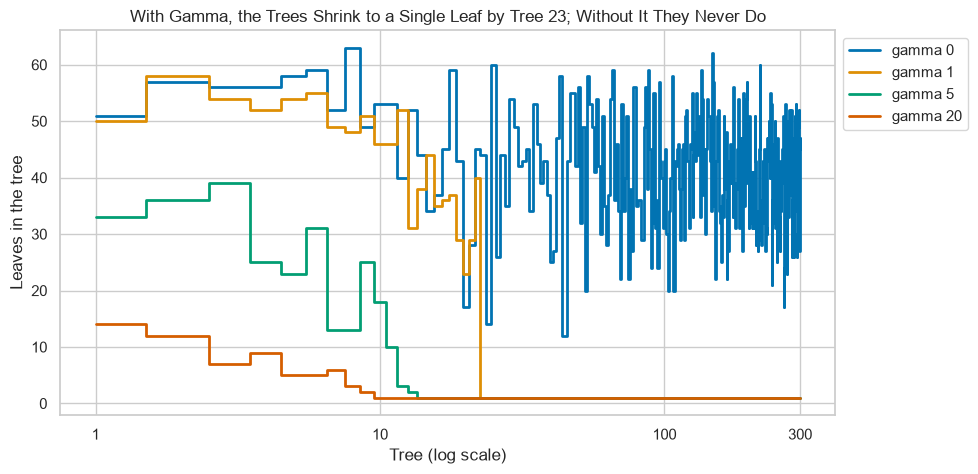

In [38]:
# the tree-size trace: the leaves in each of the 300 trees, one line per gamma
for gamma, leaves_per_tree in leaves_by_gamma.items():
    plt.step(leaves_per_tree.index + 1, leaves_per_tree.values, where="mid", linewidth=2, label=f"gamma {gamma}")
plt.xscale("log")
plt.xticks([1, 10, 100, 300], ["1", "10", "100", "300"])
plt.xlabel("Tree (log scale)")
plt.ylabel("Leaves in the tree")
plt.title("With Gamma, the Trees Shrink to a Single Leaf by Tree 23; Without It They Never Do")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

With gamma 5, 287 of the 300 trees are a single leaf, every tree from the 14th on.

Gamma 1 gets there at tree 23, gamma 20 at tree 10; gamma 0 never does.

From then on each tree shifts every account alike, so the ranking stops changing: validation ROC AUC 0.7763 against 0.7492 with no gamma.

## Brakes With Early Stopping

In [39]:
# the folds' best single brake, lambda 1000, at the smaller step, stopped on the stopping rows
braked = XGBClassifier(n_estimators=1000, learning_rate=0.05, reg_lambda=1000, eval_metric="logloss", early_stopping_rounds=50,
                       n_jobs=1, random_state=SEED)
braked.fit(X_fit, y_fit, eval_set=[(X_fit, y_fit), (X_stop, y_stop)], verbose=False)
print("Trees kept:", braked.best_iteration + 1, " Rounds run:", len(braked.evals_result()["validation_1"]["logloss"]),
      " Lowest stopping log loss:", round(braked.best_score, 4))
print("ROC AUC, fit rows:", round(roc_auc_score(y_fit, braked.predict_proba(X_fit)[:, 1]), 4),
      " validation:", round(roc_auc_score(y_valid, braked.predict_proba(X_valid)[:, 1]), 4),
      " Validation AP:", round(average_precision_score(y_valid, braked.predict_proba(X_valid)[:, 1]), 4))

Trees kept: 394  Rounds run: 444  Lowest stopping log loss: 0.4331
ROC AUC, fit rows: 0.8123  validation: 0.7812  Validation AP: 0.5539


Lambda 1000 slows every leaf, so the stop comes at 394 trees, and the stopping log loss reaches 0.4331, below both earlier stops.

Validation ROC AUC 0.7812 and average precision 0.5539, the best XGBoost so far, with the fit rows at only 0.8123.

Taking one brake from five folds is a light choice made on training rows; Day 11 tunes several at once, honestly.

**Brakes let many small steps learn slowly, and early stopping picks how many.**

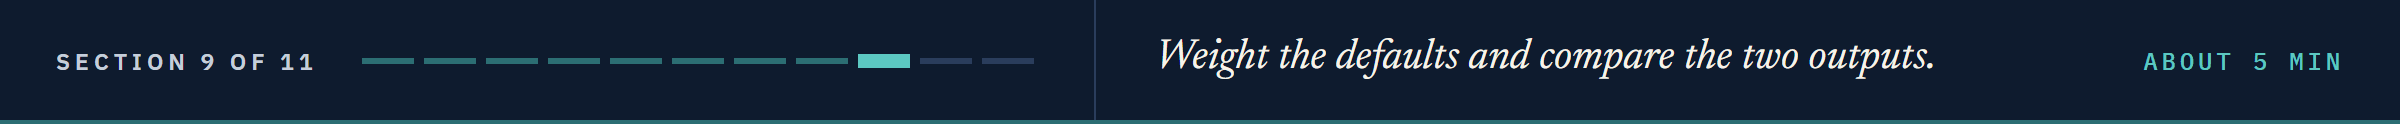

# The Rare Class

## Weighting the Defaults

`scale_pos_weight` multiplies every defaulted account's gradient and hessian, so each counts that many times in every leaf.
The course sets it to the paid accounts over the defaulted ones, as Course 4's Day 9 balanced its tree.

In [40]:
# paid accounts over defaulted accounts on the training rows
weight = (y_train == 0).sum() / (y_train == 1).sum()
print("Paid:", (y_train == 0).sum(), " Defaulted:", (y_train == 1).sum(), " Weight:", round(weight, 4))

# the braked model's average output on the validation rows, beside their default rate
braked_out = braked.predict_proba(X_valid)[:, 1]
print("Braked model's average output:", round(braked_out.mean(), 4), " Default rate:", round(y_valid.mean(), 4))

Paid: 14018  Defaulted: 3982  Weight: 3.5203
Braked model's average output: 0.2186  Default rate: 0.2212


**Predict 4**

Q. Fit the same model with every defaulted account counted 3.5203 times. What will its average output on the validation rows be? Write down a number.

## The Weighted Twin

The twin keeps the braked model's 394 trees and skips early stopping, because the stopping log loss judges a probability and a weighted model's output is not one.

In [41]:
# the braked settings and tree count, every defaulted account weighted, no early stopping
twin = XGBClassifier(n_estimators=braked.best_iteration + 1, learning_rate=0.05, reg_lambda=1000, scale_pos_weight=weight,
                     n_jobs=1, random_state=SEED).fit(X_fit, y_fit)
twin_out = twin.predict_proba(X_valid)[:, 1]
print("Average output: braked", round(braked_out.mean(), 4), " weighted", round(twin_out.mean(), 4))
print("ROC AUC: braked", round(roc_auc_score(y_valid, braked_out), 4), " weighted", round(roc_auc_score(y_valid, twin_out), 4))

Average output: braked 0.2186  weighted 0.417
ROC AUC: braked 0.7812  weighted 0.7829


Spearman's correlation is the correlation of two columns' ranks: 1 means the same order.

In [42]:
# where the twin starts: the defaulted share of the fit rows once each defaulted account counts 3.5203 times
print("Weighted default share:", round(weight * (y_fit == 1).sum() / (weight * (y_fit == 1).sum() + (y_fit == 0).sum()), 4))

# how alike the two orders are
print("Spearman's correlation:", round(pd.Series(braked_out).corr(pd.Series(twin_out), method="spearman"), 4))

Weighted default share: 0.5
Spearman's correlation: 0.9882


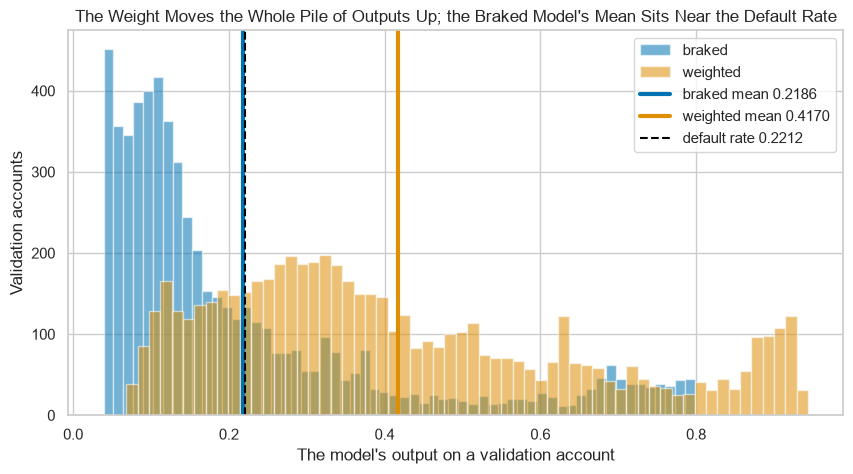

In [43]:
# both outputs on the validation rows, each mean marked, the validation default rate dashed
plt.hist(braked_out, bins=60, alpha=0.55, label="braked")
plt.hist(twin_out, bins=60, alpha=0.55, label="weighted")
plt.axvline(braked_out.mean(), color="C0", linewidth=3, label=f"braked mean {braked_out.mean():.4f}")
plt.axvline(twin_out.mean(), color="C1", linewidth=3, label=f"weighted mean {twin_out.mean():.4f}")
plt.axvline(y_valid.mean(), color="black", linestyle="--", label=f"default rate {y_valid.mean():.4f}")
plt.xlabel("The model's output on a validation account")
plt.ylabel("Validation accounts")
plt.title("The Weight Moves the Whole Pile of Outputs Up; the Braked Model's Mean Sits Near the Default Rate")
plt.legend()
plt.show()

In [44]:
# draw a confusion matrix: each cell in its own colour, with its name, its count and its share of the accounts
def draw_confusion(target, flags, ax, title):
    tn, fp, fn, tp = confusion_matrix(target, flags).ravel()
    total = tn + fp + fn + tp
    labels = [[f"TN\n{tn:,}\n{tn / total:.1%}", f"FP\n{fp:,}\n{fp / total:.1%}"],
              [f"FN\n{fn:,}\n{fn / total:.1%}", f"TP\n{tp:,}\n{tp / total:.1%}"]]
    sns.heatmap([[0, 1], [2, 3]], cmap=list(CELL_COLOURS.values()), annot=labels, fmt="", cbar=False, ax=ax, annot_kws={"size": 14},
                xticklabels=["not flagged (0)", "flagged (1)"], yticklabels=["paid (0)", "defaulted (1)"])
    ax.set(xlabel="The flag", ylabel="What happened", title=title)

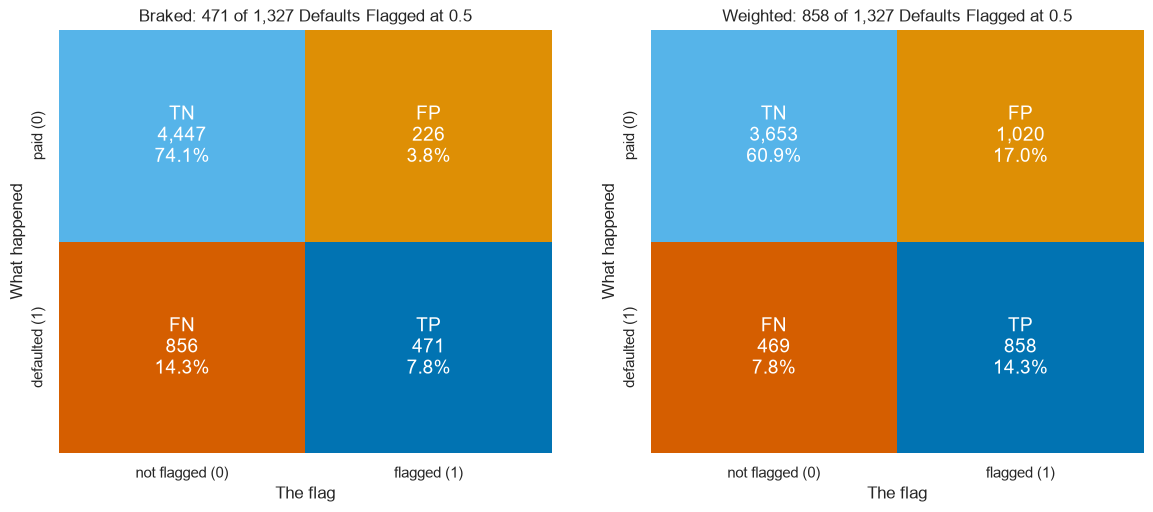

In [45]:
# each model's flags at 0.5 on the validation rows
fig, (left_ax, right_ax) = plt.subplots(1, 2, figsize=(14, 5.5))
draw_confusion(y_valid, (braked_out >= 0.5).astype(int), left_ax, "Braked: 471 of 1,327 Defaults Flagged at 0.5")
draw_confusion(y_valid, (twin_out >= 0.5).astype(int), right_ax, "Weighted: 858 of 1,327 Defaults Flagged at 0.5")
plt.show()

In [46]:
# recall and precision at 0.5, and the accounts whose flag changes
print("Recall: braked", round(recall_score(y_valid, braked_out >= 0.5), 4), " weighted", round(recall_score(y_valid, twin_out >= 0.5), 4))
print("Precision: braked", round(precision_score(y_valid, braked_out >= 0.5), 4), " weighted", round(precision_score(y_valid, twin_out >= 0.5), 4))
print("Accounts whose flag changes:", ((braked_out >= 0.5) != (twin_out >= 0.5)).sum())

Recall: braked 0.3549  weighted 0.6466
Precision: braked 0.6758  weighted 0.4569
Accounts whose flag changes: 1181


### Interpretation of the Weight

Weighted, the fit rows are half defaults, so the twin starts at 0.5 and its outputs average 0.417 against a default rate of 0.2212.

The order barely moves: Spearman's correlation 0.9882, ROC AUC 0.7829 against 0.7812.

At 0.5 recall rises from 0.3549 to 0.6466, precision falls from 0.6758 to 0.4569, and 1,181 accounts change flag.

So its output is the model's score, not a probability of default; Day 13 turns a score into a probability.

**Weighting lifts every output and barely moves the order: it changes the flags at 0.5, not the ranking.**

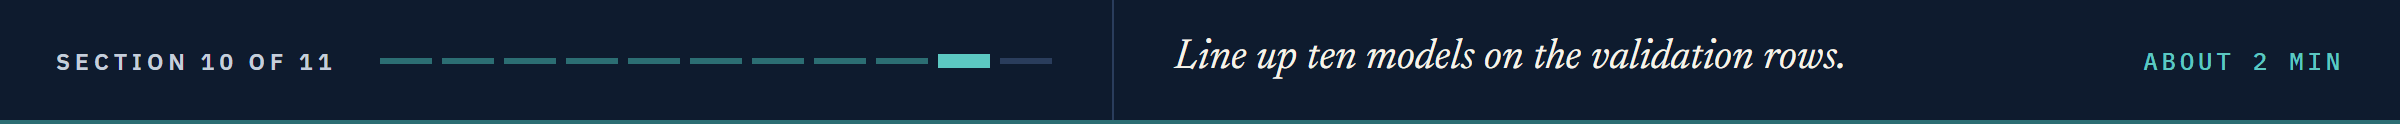

# Model Performance Comparison

## Ten Models, One Validation Set

Course 4's logistic regression and pruned tree, Day 3's chosen forest, Day 6's 200 stumps and Day 7's `GradientBoostingClassifier` at its defaults are refitted on the training rows beside today's five.

In [47]:
# ten models: five earlier ones with their own day's settings, then today's five
models = {"Logistic regression (Course 4)": Pipeline([("scale", StandardScaler()), ("logit", LogisticRegression(max_iter=1000))]),
          "Pruned tree (Course 4)": DecisionTreeClassifier(class_weight="balanced", ccp_alpha=0.001, random_state=SEED),
          "Chosen forest (Day 3)": RandomForestClassifier(n_estimators=200, max_features=8, min_samples_leaf=100,
                                                          random_state=SEED, n_jobs=1),
          "AdaBoost, 200 stumps (Day 6)": AdaBoostClassifier(n_estimators=200, random_state=SEED),
          "Gradient boosting defaults (Day 7)": GradientBoostingClassifier(random_state=SEED),
          "XGBoost defaults": xgb, "XGBoost stopped at 0.3": stop_03, "XGBoost stopped at 0.05": stop_005,
          "XGBoost braked": braked, "XGBoost weighted": twin}

# the first five are fitted here on the 18,000 training rows
for name in list(models)[:5]:
    models[name].fit(X_train, y_train)

In [48]:
# every model's validation row, with its average precision and its ROC AUC on the training rows, highest validation ROC AUC first
comparison = pd.concat([model_performance_classification(model, X_valid, y_valid) for model in models.values()])
comparison.index = list(models)
comparison["Average precision"] = [average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1]) for m in models.values()]
comparison["Training ROC AUC"] = [roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]) for m in models.values()]
comparison = comparison.sort_values("ROC AUC", ascending=False)
comparison

,ROC AUC,Accuracy,Recall,Precision,F1,Average precision,Training ROC AUC
Chosen forest (Day 3),0.7844,0.8192,0.3459,0.6790,0.4583,0.5562,0.8204
XGBoost weighted,0.7829,0.7518,0.6466,0.4569,0.5354,0.5574,0.8191
XGBoost braked,0.7812,0.8197,0.3549,0.6758,0.4654,0.5539,0.8049
Gradient boosting defaults (Day 7),0.7785,0.8215,0.3549,0.6866,0.4680,0.5396,0.8119
XGBoost stopped at 0.05,0.7767,0.8192,0.3384,0.6845,0.4528,0.5463,0.8294
"AdaBoost, 200 stumps (Day 6)",0.7708,0.8177,0.3293,0.6817,0.4441,0.5321,0.7867
XGBoost stopped at 0.3,0.7705,0.8180,0.3421,0.6746,0.4540,0.5447,0.8224
Pruned tree (Course 4),0.7627,0.7683,0.5840,0.4805,0.5272,0.4954,0.7691
XGBoost defaults,0.7592,0.8120,0.3602,0.6314,0.4587,0.5140,0.9550
Logistic regression (Course 4),0.7190,0.8123,0.2442,0.7248,0.3653,0.4946,0.7296


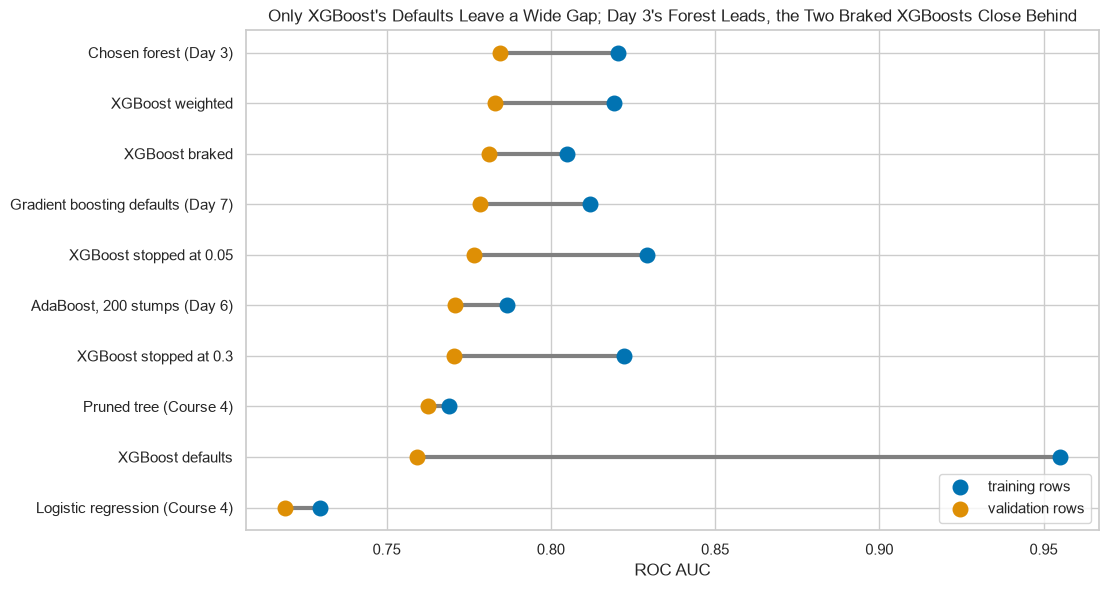

In [49]:
# the dumbbell: training against validation ROC AUC for each model, highest validation at the top
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.hlines(comparison.index, comparison["ROC AUC"], comparison["Training ROC AUC"], color="gray", linewidth=3)
ax.scatter(comparison["Training ROC AUC"], comparison.index, s=110, label="training rows", zorder=3)
ax.scatter(comparison["ROC AUC"], comparison.index, s=110, label="validation rows", zorder=3)
ax.invert_yaxis()
ax.set_xlabel("ROC AUC")
ax.set_title("Only XGBoost's Defaults Leave a Wide Gap; Day 3's Forest Leads, the Two Braked XGBoosts Close Behind")
ax.legend(loc="lower right")
plt.show()

Day 3's chosen forest ranks the validation accounts best, 0.7844; the braked XGBoost is 0.0032 behind and its weighted twin 0.0015 behind.

scikit-learn's gradient boosting at its own defaults, 0.7785, beats XGBoost's defaults, 0.7592, and its 9-tree stop, 0.7705: a library's defaults are not the method.

Recall and precision at 0.5 are not comparable across rows: the pruned tree and the twin were weighted toward defaults.

**Braked and stopped, XGBoost ranks the validation accounts within a few thousandths of Day 3's chosen forest; Day 10 asks how much of such a gap is noise.**

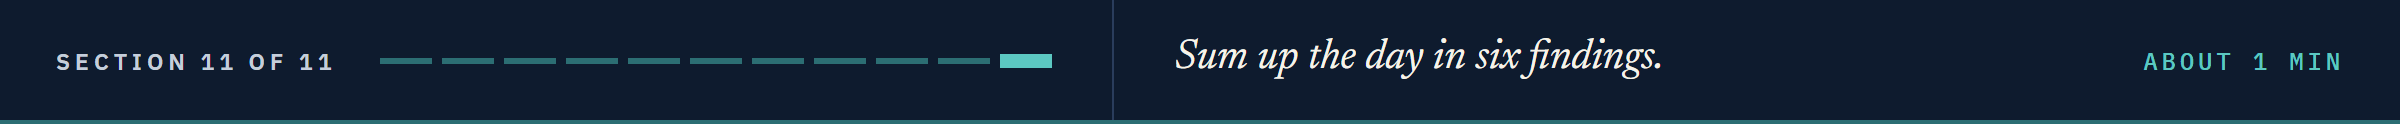

# Insights and Conclusion

XGBoost's defaults memorise: ROC AUC 0.9550 on the training rows, 0.7592 on the validation rows.

Stopping rows carved from the training rows chose the count: 9 trees at the default step, 61 at 0.05.

Lambda pulls small leaves toward zero; gamma removes weak questions and, at 5, ends the trees on its own.

On five folds the leaf penalty helped most, and row sampling did not help.

Weighting the defaults moves every output up and leaves the order nearly as it was.

No output here is a decision about an account.

**Day 9 grows trees leaf by leaf with LightGBM and stacks models.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Fit `XGBClassifier` on one thread and score it on training and validation rows.
* Follow a model's scores tree by tree with `iteration_range`.
* Carve stopping rows from the training rows and stop the trees on them with `early_stopping_rounds`.
* Rebuild a leaf's value and a split's gain from gradients and hessians, and read lambda and gamma in them.
* Compare brakes on folds inside the training rows, and weight the rare class with `scale_pos_weight`.

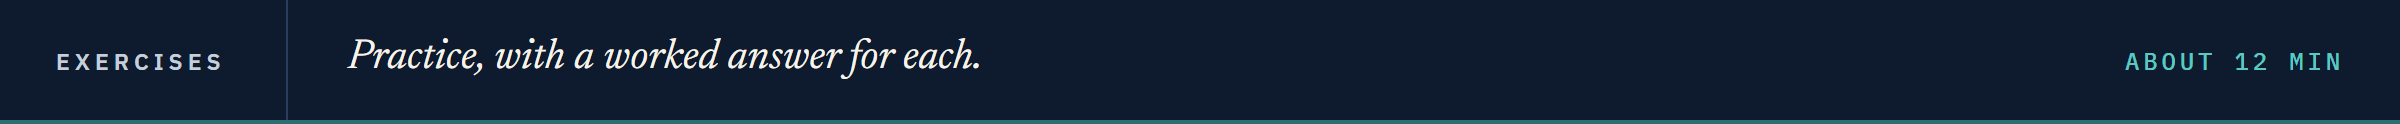

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [50]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Shallow Trees With Early Stopping**

Q. Stop a model at a learning rate of 0.05 with `max_depth=2` on the stopping rows, as in Stopping at a Smaller Step. Store the trees it keeps in `ex1_trees` and its validation ROC AUC, through `float(...)`, in `ex1_auc`.

In [51]:
# your code here
ex1_trees = ...
ex1_auc = ...

In [52]:
check("Exercise 1 the trees kept", ex1_trees, 265)
check("Exercise 1 the validation ROC AUC", ex1_auc, 0.776386046861905)

Exercise 1 the trees kept: not attempted yet
Exercise 1 the validation ROC AUC: not attempted yet


### Exercise 2

**Stopping on Average Precision**

Q. Stop the braked settings with `eval_metric="aucpr"`, XGBoost's area under the precision-recall curve, on the stopping rows. Store the trees it keeps in `ex2_trees` and its validation average precision, through `float(...)`, in `ex2_ap`.

In [53]:
# your code here
ex2_trees = ...
ex2_ap = ...

In [54]:
check("Exercise 2 the trees kept", ex2_trees, 138)
check("Exercise 2 the validation average precision", ex2_ap, 0.541050669287295)

Exercise 2 the trees kept: not attempted yet
Exercise 2 the validation average precision: not attempted yet


### Exercise 3

**A Function for the Trees Kept**

Q. Write `trees_used(model)` that returns the number of trees a stopped model keeps, and store `trees_used(braked)` in `ex3_trees`.

In [55]:
# your code here
ex3_trees = ...

In [56]:
check("Exercise 3 the braked model's trees", ex3_trees, 394)

Exercise 3 the braked model's trees: not attempted yet


### Exercise 4: AI check

**The Stop That Chose on the Report Rows**

You asked an AI assistant for a function that stops XGBoost early and reports its validation ROC AUC.
This came back.
It runs, and the score looks better than anything above.
Test it, then find the one bug.

In [57]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def early_stopped_auc(X_train, y_train, X_valid, y_valid):
    # stop the trees on held-back rows, then report the validation ROC AUC
    model = XGBClassifier(n_estimators=1000, learning_rate=0.05, reg_lambda=1000, eval_metric="auc", early_stopping_rounds=50,
                          n_jobs=1, random_state=SEED)
    model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
    return model, roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1])

ai_model, ai_auc = early_stopped_auc(X_train, y_train, X_valid, y_valid)
print("Trees kept:", ai_model.best_iteration + 1, " Validation ROC AUC:", round(ai_auc, 4))

Trees kept: 760  Validation ROC AUC: 0.7852


In [58]:
# the test: the score the stop chose on must not be the score reported, or the report rows chose the trees
assert abs(ai_model.best_score - ai_auc) > 1e-6, "the stopping score is the reported score: the validation rows chose the trees"

AssertionError: the stopping score is the reported score: the validation rows chose the trees

Q. Fix the function, and store the fixed model's trees kept in `ex4_trees` and its validation ROC AUC, through `float(...)`, in `ex4_auc`.

In [59]:
# your code here
ex4_trees = ...
ex4_auc = ...

In [60]:
check("Exercise 4 the trees kept", ex4_trees, 487)
check("Exercise 4 the validation ROC AUC", ex4_auc, 0.7818326060127355)

Exercise 4 the trees kept: not attempted yet
Exercise 4 the validation ROC AUC: not attempted yet


## Congratulations!

You ran the library most boosting work reaches for, and caught its defaults memorising 18,000 accounts.
You carved rows of your own to stop the trees on, so the validation rows stayed clean.
You rebuilt a leaf and a split by hand, and watched lambda and gamma work inside them.
In Day 9 you meet LightGBM, which grows its trees leaf by leaf, and stack models.

[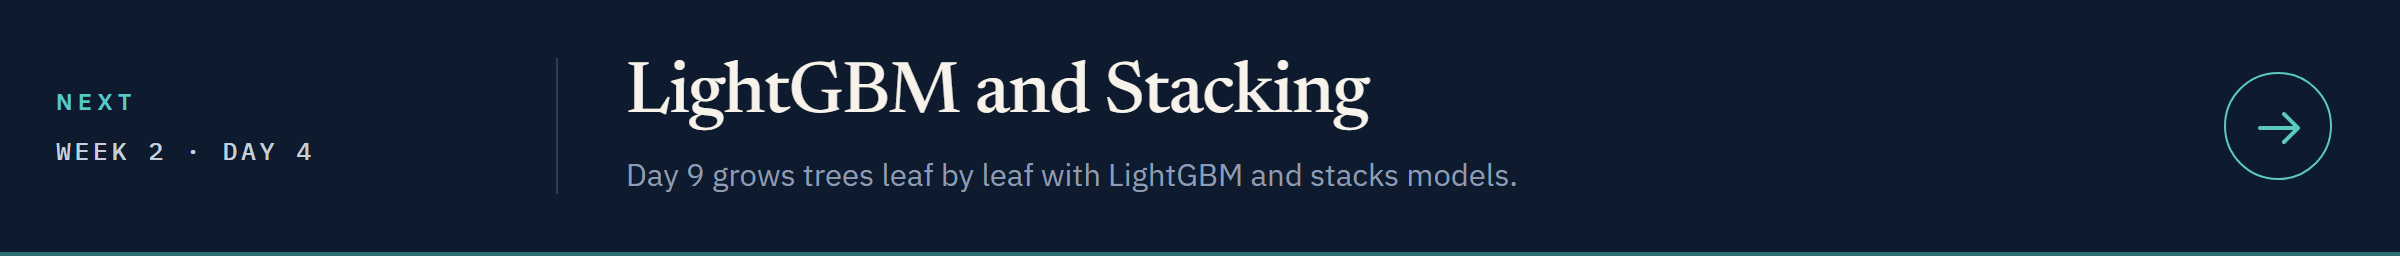](../day4/09_lightgbm_and_stacking.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week2/day4/09_lightgbm_and_stacking.ipynb)